# MeshRTC-Agents: програмні агенти роботизованих транспортних платформ, що координуються короткими командами через Meshtastic

**Цифровий двійник роботизованого транспортного комплексу (РТК) для екстреної доставки під час глибоких знеструмлень**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)
&nbsp; Версія 1.0.0 · ліцензія коду MIT, тексту й рисунків CC BY 4.0 · усі дані **синтетичні**

---

Ноутбук є програмним додатком до дослідження *«Agentic Supervisory Control of a Robotic Transport Complex for Emergency Deliveries during Deep Blackouts»* (Д. Прокопович-Ткаченко, Університет митної справи та фінансів, Дніпро) і до пропозиції статті для спецвипуску MDPI *Information* «Advanced Control Topics on Robotic Vehicles, 2nd Edition».

**Що всередині**

| Розділ | Зміст |
|---|---|
| 1 | Встановлення в Google Colab |
| 2 | Концепція: чотири рівні РТК, суспільство агентів, міграція повноважень |
| 3 | **Протокол коротких команд Meshtastic**: каталог, текстове та бінарне кодування, ефірний час LoRa, бюджет duty cycle 1 % |
| 4 | Синтетичне місто, радіомодель, покриття mesh |
| 5 | Агент-робот: Supervisory Feasibility Controller (SFC), енергетична модель, ймовірнісні обмеження |
| 6 | **Десять транспортних сценаріїв S01–S10** з картами маршрутів і діаграмами обміну командами |
| 7 | Парний Монте-Карло: S1 (зупинка) / S2 (фіксований маршрут) / S3 (SFC), регулятор ризику z |
| 8 | Флот: централізоване диспетчування проти агентного (DTN + аукціон BID/LSE) |
| 9 | **Нейрорішення N1–N4**: енергетичний ансамбль, нейрополітика зі щитом, прогноз покриття, розбір команд оператора |
| 10 | Обмеження, відтворюваність, цитування |

> ⚠️ Усі результати — виходи моделювання на синтетичних даних. Місто лише *натхненне* плануванням Верхньодніпровська і не є його картою. Результати показують умовну здійсненність і механізми, а не готовність до експлуатації.

## 1. Встановлення

Пакет `meshrtc` потребує лише `numpy`, `pandas`, `matplotlib` (усі є в Colab). Комірка нижче знаходить пакет:

1. якщо ноутбук відкрито з розпакованого архіву — використовує його;
2. якщо в `/content` лежить `MeshRTC-Agents-v1.0.0.zip` — розпаковує;
3. якщо задано `ZENODO_ZIP_URL` — завантажує архів із Zenodo;
4. інакше в Colab просить завантажити zip-файл вручну.

In [1]:
import os, sys, glob, zipfile, urllib.request

ZENODO_ZIP_URL = ""   # після публікації: https://zenodo.org/records/<ID>/files/MeshRTC-Agents-v1.0.0.zip?download=1

def find_root():
    for cand in [".", "..", "/content/MeshRTC-Agents-v1.0.0", "/content/MeshRTC-Agents"]:
        if os.path.isdir(os.path.join(cand, "meshrtc")):
            return os.path.abspath(cand)
    return None

ROOT = find_root()
if ROOT is None:
    zips = sorted(glob.glob("/content/MeshRTC-Agents*.zip") + glob.glob("MeshRTC-Agents*.zip"))
    if not zips and ZENODO_ZIP_URL:
        urllib.request.urlretrieve(ZENODO_ZIP_URL, "/content/MeshRTC-Agents-v1.0.0.zip")
        zips = ["/content/MeshRTC-Agents-v1.0.0.zip"]
    if not zips and "google.colab" in sys.modules:
        from google.colab import files
        print("Завантажте MeshRTC-Agents-v1.0.0.zip ...")
        zips = [k for k in files.upload() if k.endswith(".zip")]
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall("/content")
    ROOT = find_root()
sys.path.insert(0, ROOT)
print("project root:", ROOT)

project root: /home/user/bnt/MeshRTC-Agents


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
import meshrtc
from meshrtc import protocol as pr, viz, experiments as ex
from meshrtc.world import World, RadioFabric, ROBOT, RADIO, dijkstra
from meshrtc.sim import Config, Sim, run_paired, STRAT_NAMES
from meshrtc.scenarios import SCENARIOS, run_scenario, run_scenario_paired, get
from meshrtc.fleet import FleetLogic
from meshrtc import neural as nn

viz.setup_style()
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 60)
FIG = os.path.join(ROOT, "figures"); os.makedirs(FIG, exist_ok=True)
def save(fig, name):
    fig.savefig(os.path.join(FIG, name)); plt.show()
print("meshrtc", meshrtc.__version__)

meshrtc 1.0.0


## 2. Концепція роботизованого транспортного комплексу

Під час тривалого знеструмлення наземний робот, який везе ліки чи питну воду, може втратити зв'язок із диспетчером посеред рейсу. РТК побудовано як **суспільство агентів з обмеженою автономією**:

* **L1 — фізичний рівень:** депо з генератором і зарядними станціями, роботи доставки (UGV) з офлайн-графом вулиць і сенсорами перешкод, робот-ретранслятор зі телескопічною щоглою 10 м, пункти видачі R1–R8, пункти повернення P1–P3.
* **L2 — деградуюча комунікаційна тканина:** стільникова мережа (згасає разом із резервом базових станцій), mesh-мережа **Meshtastic** (шлюз ЦКК у ролі CLIENT_MUTE, сонячні ретранслятори ROUTER_LATE, вузли об'єктів), однорангові обміни та store-carry-forward (DTN).
* **L3 — агентний рівень керування:** оркестратор, комунікаційний агент (Comms steward), ринок флоту, бортовий агент-робот SFC і монітор безпеки.
* **L4 — людина в контурі:** оператор, порадник (розбір вільного тексту в команди, N4) з детермінованим валідатором, журнал аудиту.

Ключова ідея: **повноваження — функція зв'язності**. Коли ЦКК досяжний, він призначає і може накласти вето; при переривчастому зв'язку діє ринок оренд (lease); в ізоляції робот виконує *контингентний контракт* TSK, отриманий раніше. Монітор безпеки завжди може зупинити робота.

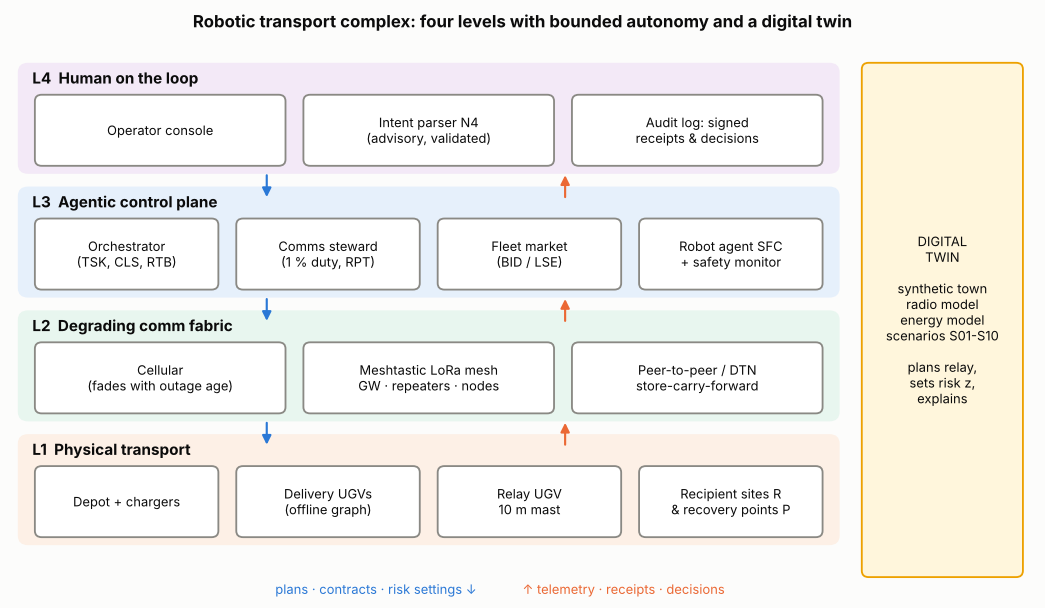

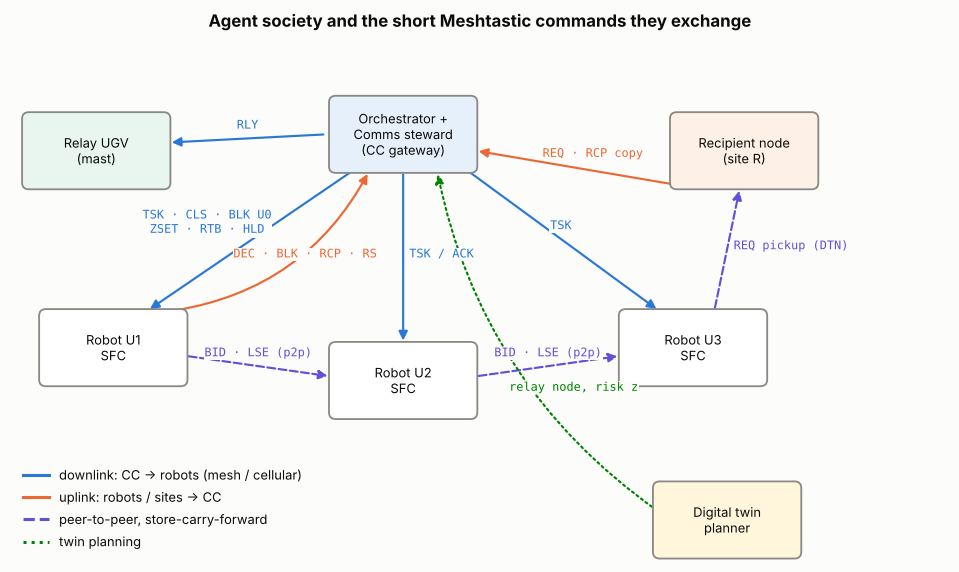

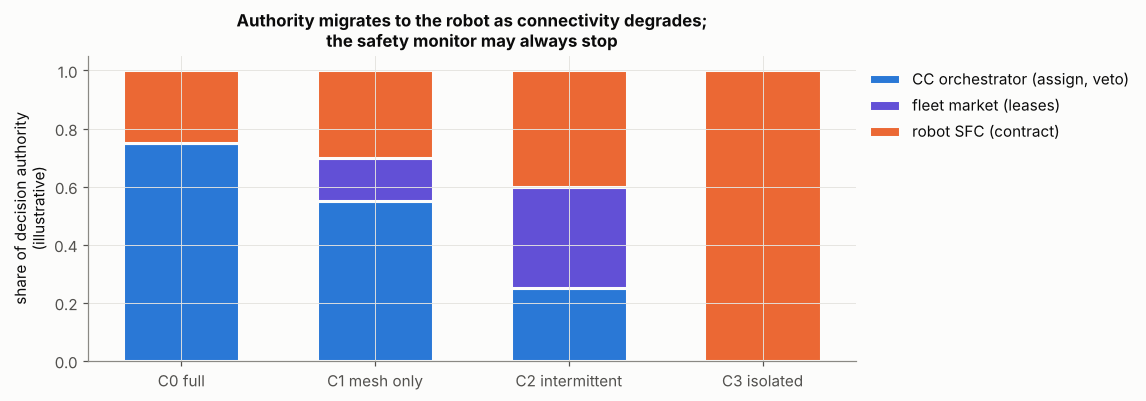

In [3]:
save(viz.architecture_diagram(), "concept_architecture.png")
save(viz.agent_society_diagram(), "concept_agent_society.png")
save(viz.authority_diagram(), "concept_authority.png")

**Режими зв'язності та поведінка комплексу**

| Режим | Ситуація | Поведінка |
|---|---|---|
| C0 повний | мережа живлення відсутня, стільниковий зв'язок і mesh працюють | ЦКК призначає завдання і може накласти вето; робот перевіряє енергію на рейс і повернення |
| C1 лише mesh | стільниковий зв'язок втрачено, вузли mesh мають автономне живлення | навігація за локальним графом; короткі повідомлення Meshtastic про закриття, перекриття, квитанції |
| C2 переривчастий | контакт з'являється «кишенями» | роботи обмінюються заявками й квитанціями P2P та DTN; ринок флоту розподіляє запасні одиниці |
| C3 ізоляція | усі зовнішні канали втрачено | виконується останній контракт: продовжити, якщо досяжні одержувач і пункт повернення; повернутися, якщо досяжний лише пункт; інакше — контрольована зупинка з маяком |

## 3. Протокол коротких команд через Meshtastic

Ефірний ресурс LoRa дуже обмежений: у діапазоні 868 МГц шлюз ЦКК може передавати лише **1 % часу — 36 с на годину**. Тому агенти обмінюються не телеметрією, а **рішеннями й контрактами** у вигляді коротких шаблонів. Кожна команда має два еквівалентні кодування:

* **текстове** — читається на будь-якому телефоні з Meshtastic (порт `TEXT_MESSAGE_APP`), напр. `TSK T17 R3 FB R5 DL1420 Z128 OW0`;
* **бінарне** — опкод + поля фіксованої довжини + CRC-16 (порт `PRIVATE_APP`), у 2–4 рази коротше.

Каталог розширює табл. 4 статті командами рівня флоту.

In [4]:
cat = pd.DataFrame(pr.CATALOGUE, columns=["op", "напрям", "ACK", "пріоритет", "meaning", "значення"])
examples = {"TSK": pr.TSK(17, 3, 5, 14*60+20), "RS": pr.RS(3, 217, 0.41, 182, 2), "DEC": pr.DEC(3, "RET", "P1", 0.27),
            "BLK": pr.BLK(3, 447), "RCP": pr.RCP(17, 3, 13*60+42, 3), "CLS": pr.CLS(3, 5), "REQ": pr.REQ(4, 1, 2, 1, 21),
            "BID": pr.BID(21, 2, 14*60+5), "LSE": pr.LSE(21, 2, 30), "RTB": pr.RTB(3, 1), "RLY": pr.RLY(9, 133),
            "ZSET": pr.ZSET(2.33), "RPT": pr.RPT(0), "ACK": pr.ACK(77), "HLD": pr.HLD(3, 30)}
cat["приклад (text)"] = cat.op.map(lambda o: examples[o].text())
cat["text, B"] = cat.op.map(lambda o: len(examples[o].text()))
cat["binary, B"] = cat.op.map(lambda o: len(examples[o].binary()))
cat["hex"] = cat.op.map(lambda o: examples[o].binary().hex(" "))
cat

,op,напрям,ACK,пріоритет,meaning,значення,приклад (text),"text, B","binary, B",hex
0,TSK,CC -> robot,True,RELIABLE,contingent task contract,контракт завдання,TSK T17 R3 FB R5 DL1420 Z128 OW0,32,11,01 11 00 03 05 5c 03 80 00 40 1c
1,RS,robot -> all,False,BACKGROUND,status beacon (heartbeat),маяк стану,RS U3 N217 S41 E182 M2,22,10,02 03 d9 00 29 b6 00 02 68 22
2,DEC,robot -> CC,True,RELIABLE,"decision report (RETURN, HOLD, STOP ...)",звіт про рішення,DEC U3 RET P1 S27,17,7,03 03 02 01 1b 09 9a
3,BLK,robot -> CC,True,RELIABLE,sensed blockage of a street segment,перекриття ділянки,BLK U3 E447,11,6,04 03 bf 01 73 09
4,RCP,robot -> CC,True,RELIABLE,delivery receipt co-signed by recipient PIN,квитанція видачі,RCP T17 R3 1342 PIN+ U3,23,10,05 11 00 03 36 03 01 03 3a 49
5,CLS,CC -> all,False,DEFAULT,"site closed, alternative site",закриття пункту,CLS R3 ALT R5,13,5,06 03 05 ca 7b
6,REQ,site -> CC,True,RELIABLE,delivery request from a recipient node,заявка пункту,REQ T21 R4 Q1 C2 PR1,20,9,07 15 00 04 01 02 01 8d 3a
7,BID,robot -> robots,False,DEFAULT,auction bid (ETA) for a request,ставка аукціону,BID T21 U2 ETA1405,18,8,08 15 00 02 4d 03 cc 01
8,LSE,robot/CC -> all,True,RELIABLE,lease: request taken by a unit,оренда заявки,LSE T21 U2 TTL30,16,7,09 15 00 02 1e 0f 8b
9,RTB,CC -> robot,True,MAX,recall / veto: return to point,відкликання,RTB U3 P1,9,5,0a 03 01 2f 4e


**Кодування / декодування і валідатор.** Будь-яка команда, створена нейромережею чи мовною моделлю, проходить детермінований валідатор `pr.validate()` перед відправленням. Бінарний кадр із пошкодженим байтом відкидається за CRC.

In [5]:
c = pr.TSK(task=17, site=3, alt=5, deadline=14*60+20, z=1.28, oneway=False)
t, b = c.text(), c.binary()
print("text  :", t, f"({len(t)} B)")
print("binary:", b.hex(" "), f"({len(b)} B)")
print("decode text  ->", pr.decode_text(t).f)
print("decode binary->", pr.decode_binary(b).f)
bad = bytearray(b); bad[3] ^= 0x40
try:
    pr.decode_binary(bytes(bad))
except ValueError as e:
    print("corrupted frame rejected:", e)
print("validator:", pr.validate(pr.TSK(18, 3, 3, 900)), "|", pr.validate(pr.RTB(2, 1)))

text  : TSK T17 R3 FB R5 DL1420 Z128 OW0 (32 B)
binary: 01 11 00 03 05 5c 03 80 00 40 1c (11 B)
decode text  -> {'task': 17, 'site': 3, 'alt': 5, 'deadline': 860, 'z': 128, 'oneway': 0}
decode binary-> {'task': 17, 'site': 3, 'alt': 5, 'deadline': 860, 'z': 128, 'oneway': 0}
corrupted frame rejected: CRC mismatch
validator: ['fallback equals recipient'] | []


### 3.1 Ефірний час LoRa

Час у ефірі кадру з корисним навантаженням $PL$ байт (Semtech, рівн. 1 статті):

$$T_{air} = (n_{pre}+4.25)\,T_s + \Big[8+\max\Big(\Big\lceil \tfrac{8PL-4SF+28+16\,CRC-20\,IH}{4(SF-2DE)}\Big\rceil (CR+4),\,0\Big)\Big]T_s,\qquad T_s=\frac{2^{SF}}{BW}$$

з преамбулою 16 символів, явним заголовком, CRC, CR 4/5, BW = 250 кГц для пресетів SHORT_FAST (SF7), MEDIUM_FAST (SF9), LONG_FAST (SF11). Перевірка: маршрутне підтвердження (ACK) займає 37.5 / 130 / 477 мс — як у статті.

SHORT_TURBO  ACK    18.8 ms   TSK text    26.4 ms   TSK binary    18.8 ms
SHORT_FAST   ACK    37.5 ms   TSK text    52.9 ms   TSK binary    37.5 ms
MEDIUM_FAST  ACK   129.5 ms   TSK text   170.5 ms   TSK binary   129.5 ms
LONG_FAST    ACK   477.2 ms   TSK text   600.1 ms   TSK binary   436.2 ms
LONG_SLOW    ACK  2498.6 ms   TSK text  3547.1 ms   TSK binary  2498.6 ms


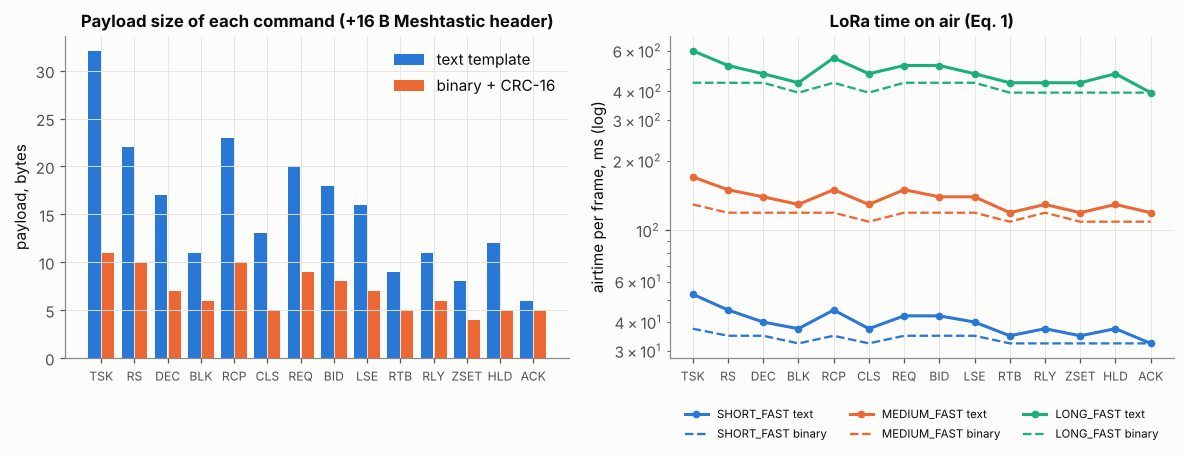

In [6]:
for p in ["SHORT_TURBO", "SHORT_FAST", "MEDIUM_FAST", "LONG_FAST", "LONG_SLOW"]:
    print(f"{p:12s} ACK {pr.lora_airtime(pr.ACK_FRAME_B, p)*1000:7.1f} ms   TSK text {pr.frame_airtime(32, p)*1000:7.1f} ms"
          f"   TSK binary {pr.frame_airtime(11, p)*1000:7.1f} ms")
save(viz.protocol_size_figure(), "protocol_sizes_airtime.png")

### 3.2 Бюджет duty cycle шлюзу ЦКК

Завантаження шлюзу з $N_r$ роботами (рівн. 2): $U = U_0 + \dfrac{N_r\,\tau_r}{3600\,\delta}\cdot 100\%$, де $U_0$ — фонове навантаження від об'єктів критичної інфраструктури (29.5 % у піковому режимі), $\tau_r$ — ефірний час шлюзу на одного робота за годину, $\delta = 0.01$.

* **Періодичні звіти** (статус щохвилини з ACK) вичерпують спільний шлюз приблизно при 30 роботах (SHORT_FAST), а виділений шлюз MEDIUM_FAST — уже при ~4.
* **Звіти за подіями** (маяк без ACK, підтверджуються лише контракти, квитанції, перекриття й рішення) дозволяють обслуговувати > 100 роботів.

Тому Comms steward примусово вмикає звіти за подіями командою `RPT 0` (сценарій S09).

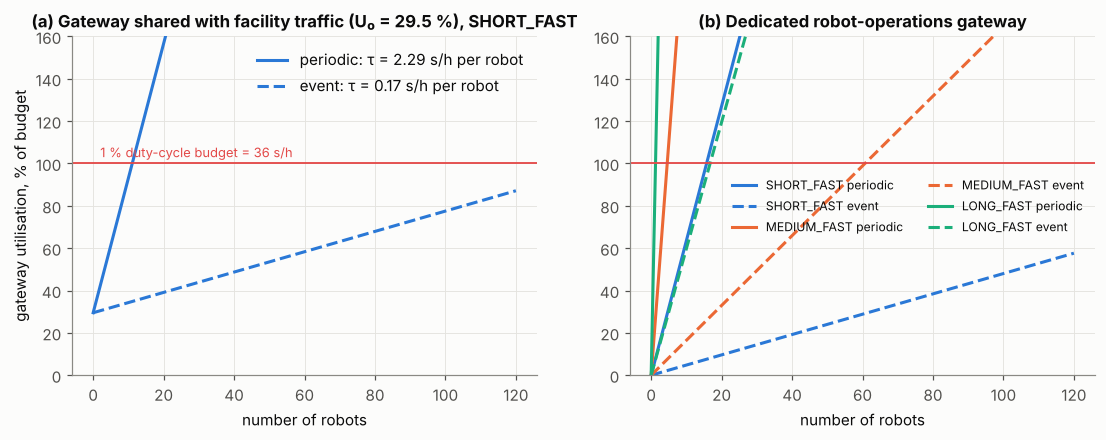

SHORT_FAST   periodic tau_r =  2.288 s/h -> max robots on dedicated gateway: 15
SHORT_FAST   event    tau_r =  0.173 s/h -> max robots on dedicated gateway: 208
MEDIUM_FAST  periodic tau_r =  7.899 s/h -> max robots on dedicated gateway: 4
MEDIUM_FAST  event    tau_r =  0.593 s/h -> max robots on dedicated gateway: 60
LONG_FAST    periodic tau_r = 29.065 s/h -> max robots on dedicated gateway: 1
LONG_FAST    event    tau_r =  2.152 s/h -> max robots on dedicated gateway: 16


In [7]:
save(viz.airtime_budget_figure(), "airtime_budget.png")
for p in ["SHORT_FAST", "MEDIUM_FAST", "LONG_FAST"]:
    for pol in ["periodic", "event"]:
        tau = pr.tau_per_robot(p, pol)
        print(f"{p:12s} {pol:8s} tau_r = {tau:6.3f} s/h -> max robots on dedicated gateway: {int(36/tau)}")

## 4. Синтетичне місто і радіомодель

Двійник генерує прибережне місто ≈ 7 × 4.75 км на березі водосховища: решітка вулиць 250 м з розкидом, магістралі, місцеві та ґрунтові дороги (коефіцієнти кочення 0.018 / 0.025 / 0.045, швидкості 1.8 / 1.6 / 1.2 м/с), рельєф, що підіймається від берега, і два яри.

Запас лінії між роботом у вузлі $x$ та інфраструктурним вузлом $j$ (Окамура–Хата, 868 МГц):

$$M_{xj} = P_{EIRP} - L_H(d_{xj}, h_j, h_r) + G - \ell - L_{ex} + \xi_x + \zeta_{xj} - P_{thr}$$

$P_{EIRP}=15$ дБм, $P_{thr}=-118$ дБм, $\xi$ — гладке поле забудови, $\zeta\sim N(0,6^2)$ — затінення сценарію; перевірка контакту успішна, якщо $\max_j M_{xj} + \nu > 0$, $\nu \sim N(0,4^2)$. Ретранслятори розміщує жадібний алгоритм; пакети проходять не більше `hop_limit = 3` ретрансляцій.

street nodes 490, segments 869, network length 254 km


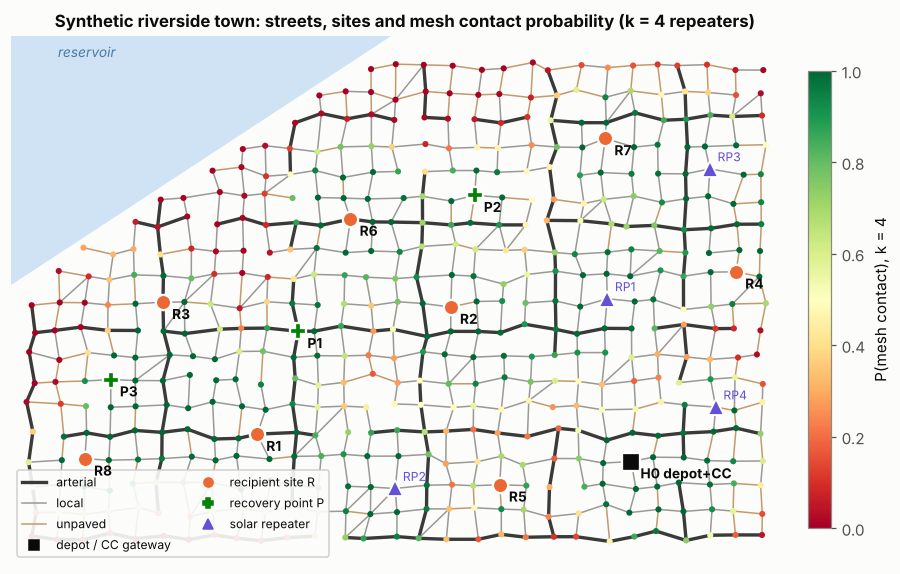

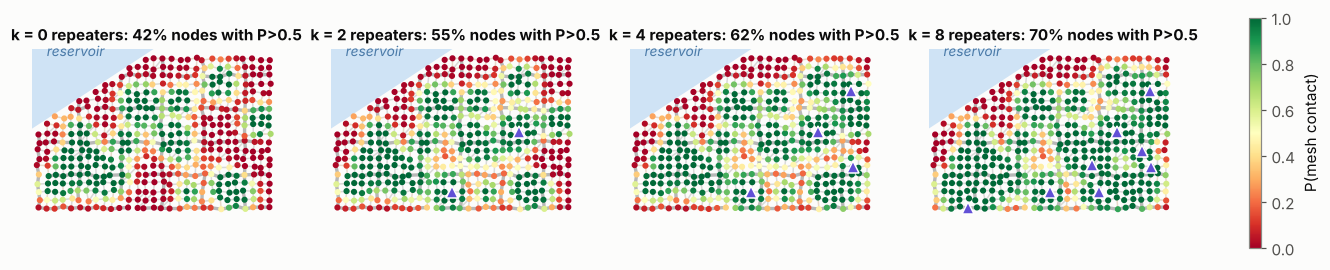

In [8]:
w = World()
print(f"street nodes {w.n}, segments {len(w.edges)}, network length {w.elen.sum()/1000:.0f} km")
fab = RadioFabric(w, k=4)
fig, ax = plt.subplots(figsize=(11, 7.2))
viz.plot_town(w, ax, value=fab.contact_probability(), vlabel="P(mesh contact), k = 4", repeaters=fab.repeaters)
ax.set_title("Synthetic riverside town: streets, sites and mesh contact probability (k = 4 repeaters)")
save(fig, "town_coverage_k4.png")
save(viz.plot_coverage_panels(w), "coverage_vs_repeaters.png")

## 5. Агент-робот: Supervisory Feasibility Controller

**Енергія дуги** $a$ довжиною $L_a$, з підйомом $\Delta z_a$, коефіцієнтом кочення $c_a$, сніговим фактором $s$ і фактором швидкості $\kappa$ (рівн. 3):

$$e_a(s,\kappa)=\frac{1}{3600}\Big[\psi\big(mg(c_a s L_a+\Delta z_a)\big)+\frac{P_{aux}L_a}{\kappa v_a}\Big],\quad \psi(W)=\begin{cases}W/\eta_d,&W\ge 0\\ \eta_r W,&W<0\end{cases}$$

**Онлайн-калібрування** (рівн. 4): $\hat r_t = \dfrac{w_0+\sum_{a\in\mathcal H_t} e_a}{w_0+\sum_{a\in\mathcal H_t}\hat e_a}$, $w_0 = 20$ Вт·год.

**Ймовірнісна потреба енергії** на шлях $\pi$ (рівн. 5):

$$N(\pi)=\hat r_t\mu_\pi+z\sqrt{\sum_{a\in\pi}(\sigma_e\hat e_a)^2+(\sigma_r\hat r_t\mu_\pi)^2}+\epsilon\,C(T)$$

**Предикати** (рівн. 6): $F_D$ — доставити і дійти до пункту повернення; $F_R$ — дійти до пункту повернення зараз; $F_H$ — дійти хоча б до одержувача (лише при дозволі односторонньої доставки).

Справжнє споживання в двійнику містить ефекти, яких фізична модель планувальника **не знає**: різну реакцію покриттів на сніг, падіння ККД приводу на морозі, навантаження на обігрів. Калібрування $\hat r_t$ і нейроансамбль N1 (розділ 9) компенсують цю похибку.

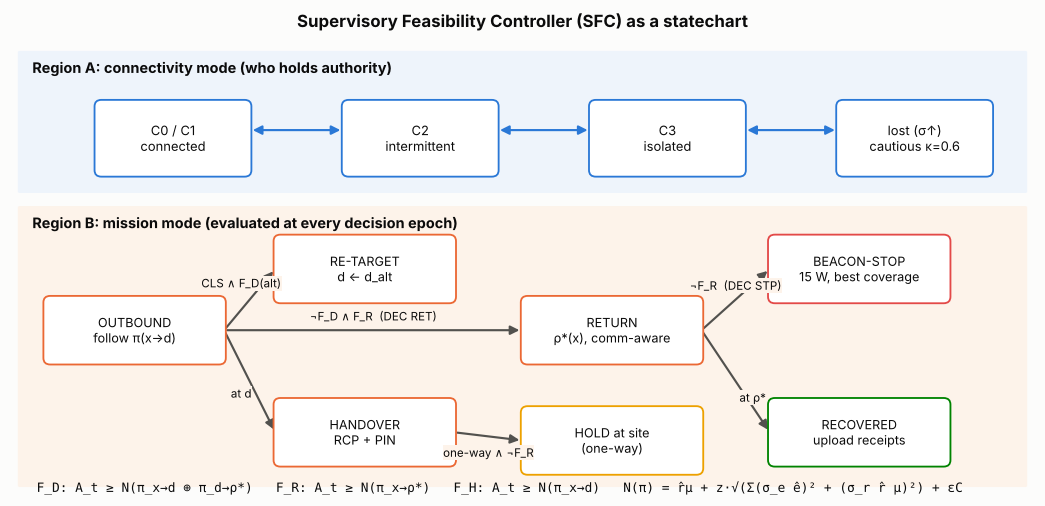

,parameter,value
0,"loaded mass, kg",140.0
1,"battery C0, Wh",900.0
2,cut-off / reserve,8 % / 3 % of C(T)
3,eta_d / eta_r,0.72 / 0.25
4,"P_aux move / idle / beacon, W",70 / 38 / 15
5,risk level z (default),1.28
6,sigma_e,0.1
7,cautious kappa,0.6
8,"EIRP / threshold, dBm",15 / -118
9,"shadowing / fading, dB",6 / 4


In [9]:
save(viz.statechart_diagram(), "sfc_statechart.png")
pd.DataFrame([("loaded mass, kg", ROBOT["mass"]), ("battery C0, Wh", ROBOT["cap"]), ("cut-off / reserve", "8 % / 3 % of C(T)"),
              ("eta_d / eta_r", f"{ROBOT['eta_d']} / {ROBOT['eta_r']}"), ("P_aux move / idle / beacon, W", "70 / 38 / 15"),
              ("risk level z (default)", ROBOT["z"]), ("sigma_e", ROBOT["sigma_e"]), ("cautious kappa", ROBOT["kappa_c"]),
              ("EIRP / threshold, dBm", "15 / -118"), ("shadowing / fading, dB", "6 / 4")], columns=["parameter", "value"])

**Ландшафт рішень SFC.** Для робота в депо обчислимо доступну енергію та потребу $N$ для кожного пункту при різному заряді: де $A_t \ge N(\pi_{x\to d}\oplus\pi_{d\to\rho^*})$, SFC приймає завдання, інакше — відмовляється (DCL) і повертає завдання оркестратору.

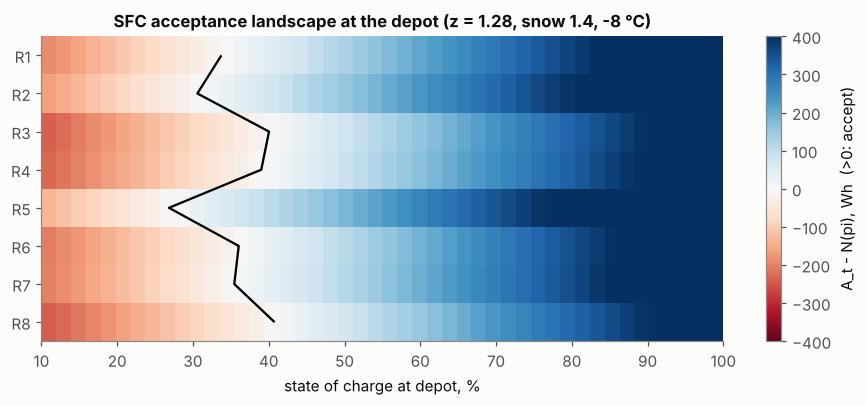

In [10]:
cfg = Config(soc0=0.5, snow=1.4, temp=-8, b=0.0, p_close=0, gnss_denied=False)
sim = Sim(w, cfg, seed=1); rob = sim.robots[0]
socs = np.linspace(0.1, 1.0, 46); sites = [f"R{i}" for i in range(1, 9)]
M = np.zeros((len(sites), len(socs)))
for i, s in enumerate(sites):
    mu, var = rob.planner.chain(w.depot, [w.sites[s].node], 1.0)
    for j, soc in enumerate(socs):
        rob.E = soc * rob.cap
        M[i, j] = rob.avail() - rob.planner.need(mu, var)
fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(M, aspect="auto", cmap="RdBu", vmin=-400, vmax=400, extent=[socs[0]*100, socs[-1]*100, len(sites)-0.5, -0.5])
ax.contour(socs*100, np.arange(len(sites)), M, levels=[0], colors="k", linewidths=1.5)
ax.set_yticks(range(len(sites)), sites); ax.set_xlabel("state of charge at depot, %"); ax.grid(False)
plt.colorbar(im, label="A_t - N(pi), Wh  (>0: accept)"); ax.set_title("SFC acceptance landscape at the depot (z = 1.28, snow 1.4, -8 °C)")
save(fig, "sfc_landscape.png")

## 6. Десять транспортних сценаріїв

Кожен сценарій — декларативний `Config`. Запуск показує **маршрут** (білі кружки — вузли без зв'язку, червоні хрестики — перекриття), **журнал рішень** агента та **діаграму послідовності** коротких команд, які пройшли через Meshtastic (`mesh`), стільникову мережу (`cell`), однорангові канали (`p2p`) або були вивантажені в пункті повернення (`dock`).

In [11]:
pd.DataFrame([(k, v["cfg"].title, v["ua"]) for k, v in SCENARIOS.items()], columns=["id", "title", "опис"])

,id,title,опис
0,S01,"Medicine delivery, full connectivity (C0)",Доставка ліків (інсулін) до пункту R3; стільниковий зв'я...
1,S02,Site closure and re-targeting over the mesh (C1),Мобільний зв'язок зник (C1). Пункт R2 закривається на 12...
2,S03,"Unknown blockages: sense, report, detour","15 % ділянок перекрито (завали, повалені дерева), ЦКК пр..."
3,S04,Isolated robot with low charge (C3),"Повна ізоляція (C3): мережа і mesh недоступні, заряд 42 ..."
4,S05,GNSS denied: localisation guard and cautious mode,Супутникова навігація недоступна. Невизначеність положен...
5,S06,Fleet shift with intermittent contact (C2): centralized ...,"Зміна 8 год, 4 роботи, заявки REQ від пунктів. Централіз..."
6,S07,Relay UGV with a 10 m telescopic mast restores coverage,Без ретрансляторів і мобільного зв'язку. Планувальник дв...
7,S08,Water multi-drop with heavy load: drop-stop decisions,"Розвезення питної води на три пункти, вантаж 30 кг, -14 ..."
8,S09,Airtime surge: periodic vs event-driven reporting,"Шість роботів звітують щохвилини з підтвердженням, шлюз ..."
9,S10,Operator recall and risk dial (human on the loop),"Оператор підвищує рівень ризику (ZSET 233), тимчасово ут..."


In [12]:
def show(sim, sid, seq_msgs=22, t_max=None):
    fig, ax = plt.subplots(figsize=(12, 7.4))
    viz.plot_mission(sim, ax, title=f"{sid}: {sim.cfg.title}")
    save(fig, f"scenario_{sid}_map.png")
    ax = viz.sequence_diagram(sim, max_msgs=seq_msgs, t_max=t_max)
    ax.set_title(f"{sid}: short commands over the air (status beacons RS omitted)")
    save(ax.figure, f"scenario_{sid}_sequence.png")
    if not sim.cfg.fleet:
        display(pd.DataFrame(sim.mission_metrics())[["robot", "strategy", "terminal", "valid", "on_time", "soc_end",
                                                      "dist_km", "lat", "n_packets", "airtime_s"]].round(2))
    rows = [(r.name, f"{t:.1f}", n, code, info, f"{soc:.0%}") for r in sim.robots for (t, n, code, info, soc) in r.decisions]
    display(pd.DataFrame(rows, columns=["agent", "t, min", "node", "decision", "info", "SoC"]).head(25))

### S01 — доставка ліків при повному зв'язку (C0)
ЦКК надсилає контракт `TSK`, робот підтверджує `ACK`, періодично мовить маяк `RS`, після видачі надсилає квитанцію `RCP ... PIN+`, підписану PIN-кодом одержувача.

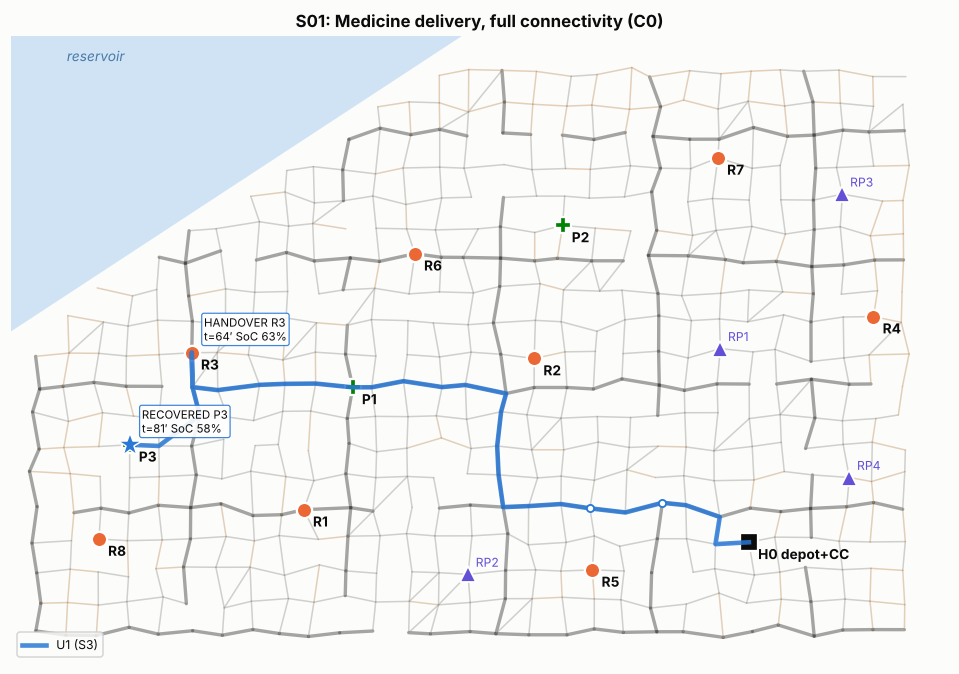

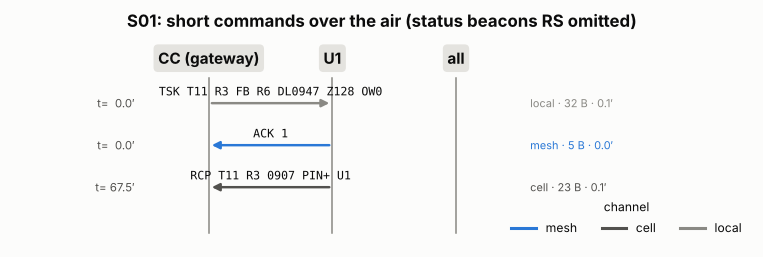

,robot,strategy,terminal,valid,on_time,soc_end,dist_km,lat,n_packets,airtime_s
0,U1,S3,recovered,1,1,0.58,8.21,0.11,10,0.43


,agent,"t, min",node,decision,info,SoC
0,U1,64.5,266,HANDOVER,R3,63%
1,U1,80.7,177,RECOVERED,P3,58%


In [13]:
show(run_scenario(w, "S01"), "S01")

### S02 — закриття пункту і перенацілювання через mesh (C1)
Стільниковий зв'язок відсутній. Пункт R2 закривається на 12-й хвилині; ЦКК розсилає `CLS R2 ALT R7`. SFC перевіряє $F_D$ для альтернативи й відповідає `DEC U1 RTG R7`.

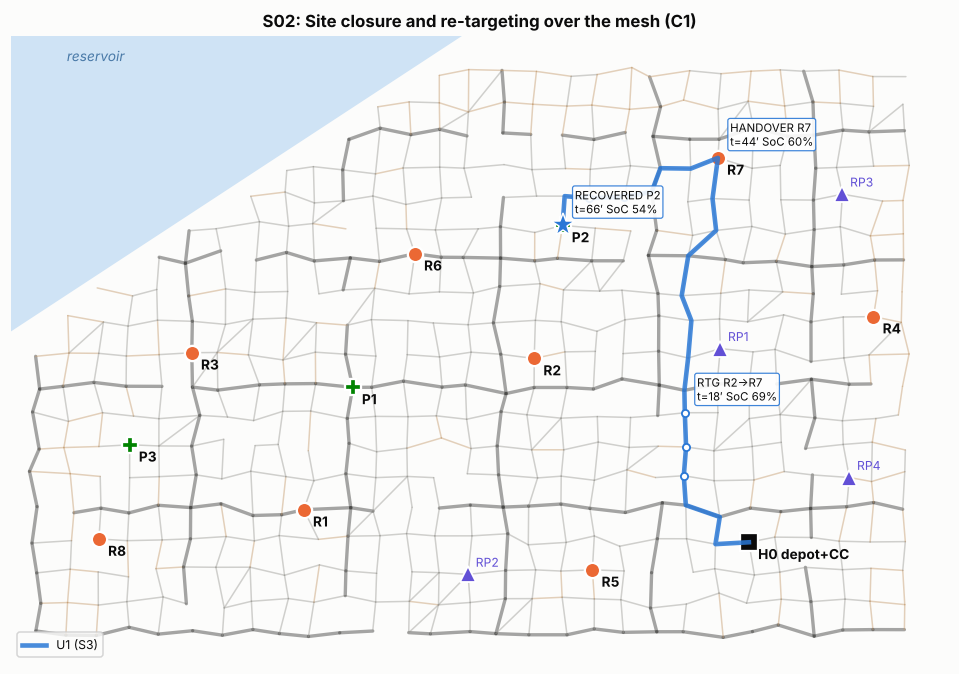

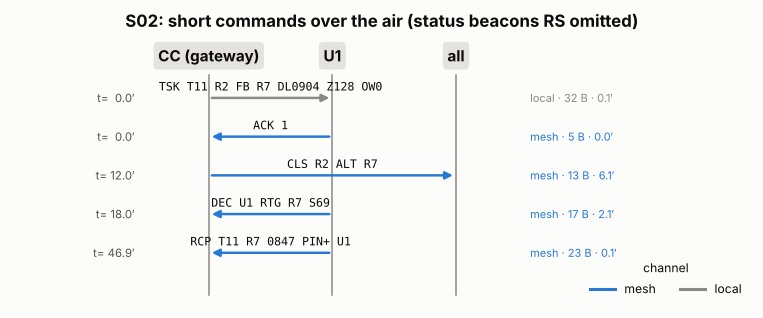

,robot,strategy,terminal,valid,on_time,soc_end,dist_km,lat,n_packets,airtime_s
0,U1,S3,recovered,1,1,0.54,6.14,0.07,8,0.8


,agent,"t, min",node,decision,info,SoC
0,U1,18.0,224,RTG,R2->R7,69%
1,U1,43.9,430,HANDOVER,R7,60%
2,U1,66.4,382,RECOVERED,P2,54%


In [14]:
show(run_scenario(w, "S02"), "S02")

### S03 — невідомі перекриття: виявити, повідомити, об'їхати
15 % ділянок перекрито кластерами; ЦКК про них не знає (дізнається з затримкою ~Exp(40 хв) і розсилає `BLK U0 E…`). Робот виявляє перекриття сенсорами, надсилає `BLK U1 E…` і переплановує шлях.

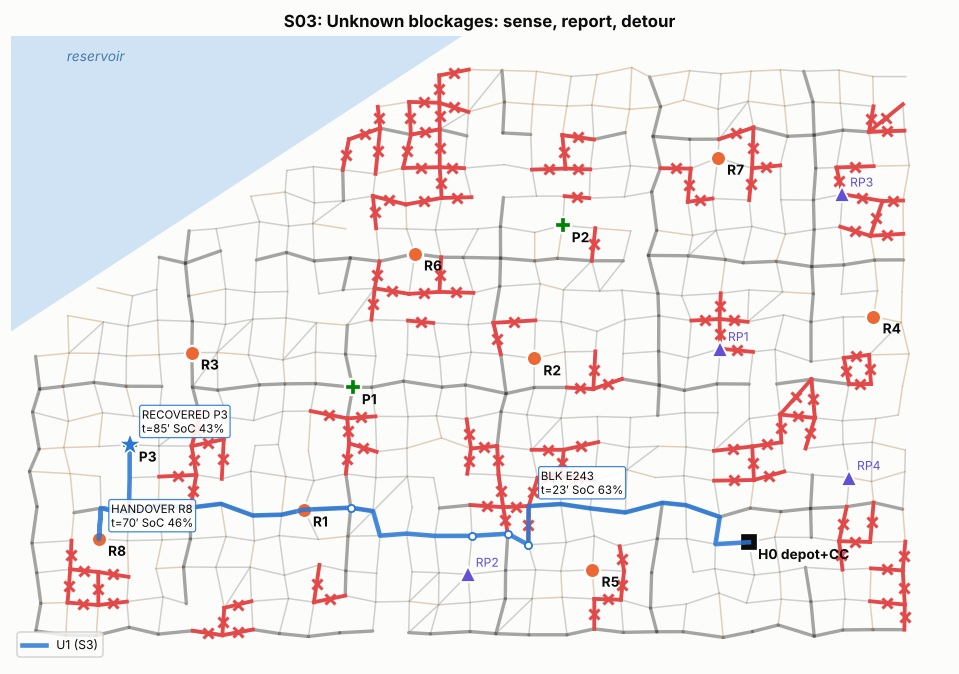

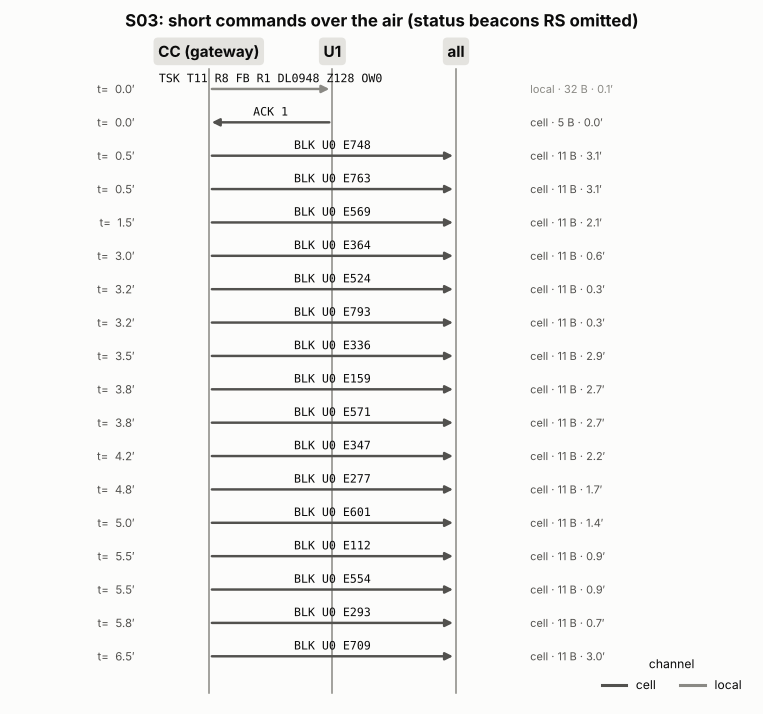

,robot,strategy,terminal,valid,on_time,soc_end,dist_km,lat,n_packets,airtime_s
0,U1,S3,recovered,1,1,0.43,8.34,0.11,12,1.03


,agent,"t, min",node,decision,info,SoC
0,U1,22.7,132,BLK,E243,63%
1,U1,70.2,89,HANDOVER,R8,46%
2,U1,84.6,177,RECOVERED,P3,43%


In [15]:
show(run_scenario(w, "S03"), "S03", seq_msgs=18)

### S04 — ізольований робот з низьким зарядом (C3): S1 vs S2 vs S3
Mesh заглушено, стільникова мережа відсутня, заряд 42 %, сильний сніг, −12 °C. Три стратегії на **тому самому** сценарії (спільні випадкові числа):
* **S1 Stop-on-loss** зупиняється при втраті зв'язку й чекає — розряджається на холостому ходу;
* **S2 Fixed-route** доставляє, але не має резерву на повернення;
* **S3 SFC** відмовляється в депо (`DEC U1 DCL H0`) — завдання повертається оркестратору для краще зарядженого робота.
* **S3 з дозволом односторонньої доставки** (`OW1`) вирушає з планом залишитися на пункті (`ONEWAY`), але після кількох ділянок онлайн-калібрування $\hat r_t$ показує, що навіть $F_H$ не виконується, і робот повертається (`DEC RET`) — приклад того, як калібрування виправляє оптимістичний прогноз.

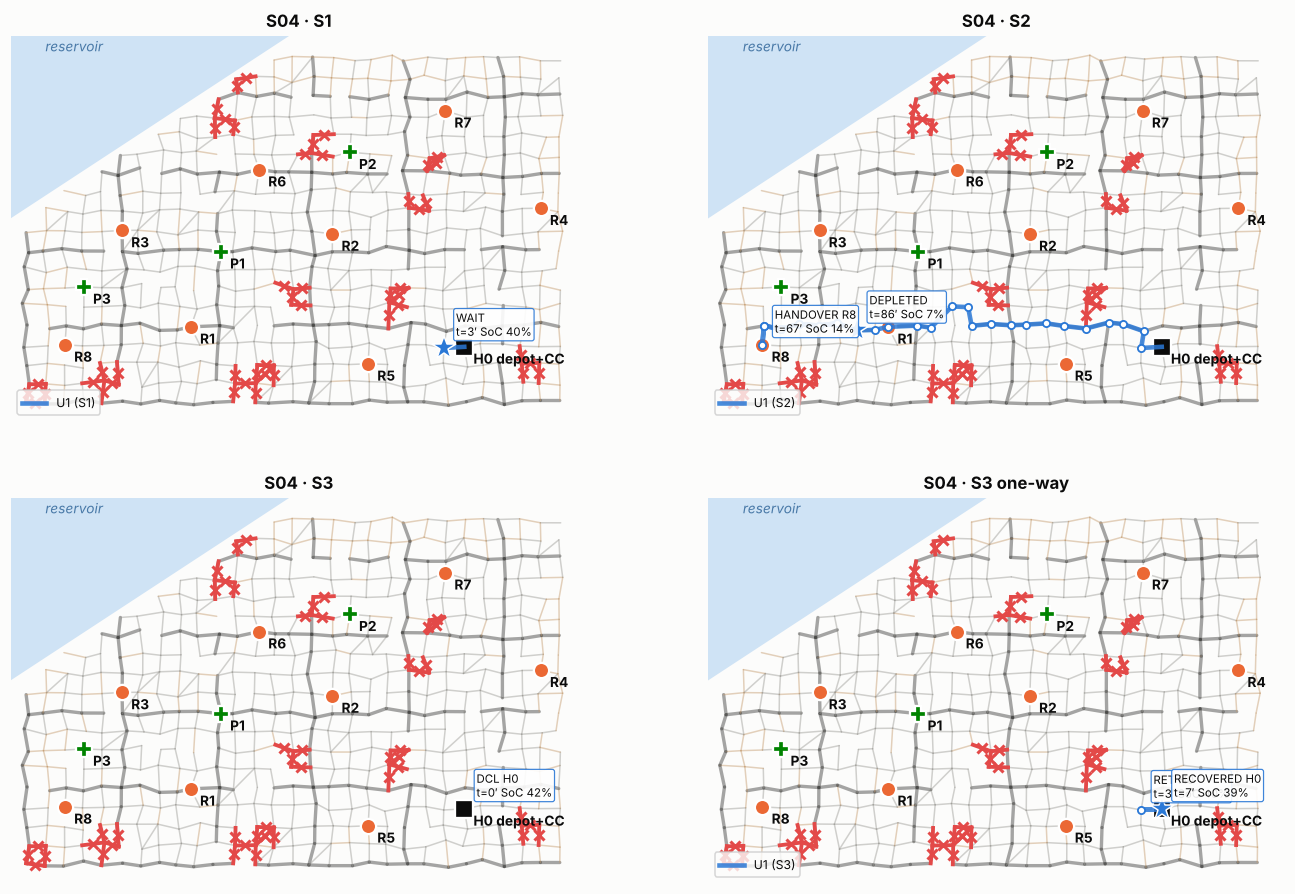

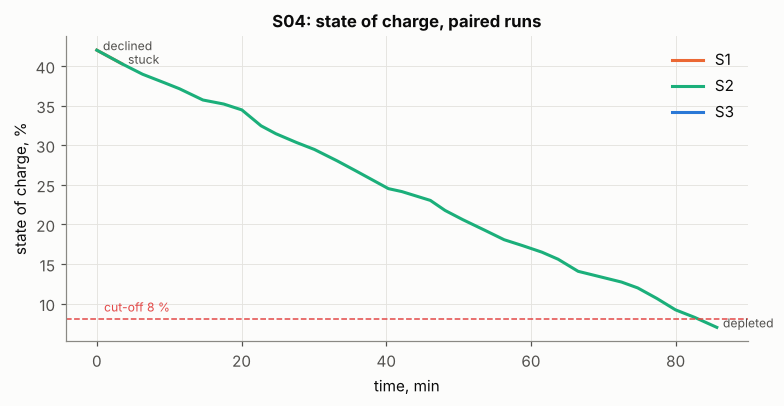

,strategy,terminal,valid,soc_end,dist_km,stranded
0,S1,stuck,0,0.10,0.33,True
1,S2,depleted,1,0.07,8.64,True
2,S3,declined,0,0.42,0.00,False
3,S3 one-way,recovered,0,0.39,0.66,False


In [16]:
out = run_scenario_paired(w, "S04")
out["S3 one-way"] = run_scenario(w, "S04", oneway=True)
fig, axs = plt.subplots(2, 2, figsize=(15, 10))
for ax, (s, sim) in zip(axs.ravel(), out.items()):
    viz.plot_mission(sim, ax, title=f"S04 · {s}")
save(fig, "scenario_S04_paired.png")
fig, ax = plt.subplots(figsize=(8, 3.6)); viz.plot_energy({k: v for k, v in out.items() if k != "S3 one-way"}, ax)
ax.set_title("S04: state of charge, paired runs"); save(fig, "scenario_S04_soc.png")
pd.DataFrame([dict(strategy=k, **{c: v.mission_metrics()[0][c] for c in ["terminal", "valid", "soc_end", "dist_km", "stranded"]})
              for k, v in out.items()]).round(2)

### S05 — GNSS недоступна: охоронець локалізації
Невизначеність положення росте з одометричним дрейфом $\sigma_{j+1}^2=\sigma_j^2+(\delta_o L_a)^2$ і скидається зіставленням з картою на перехрестях. При $\sigma > 5$ м SFC сповільнюється до $\kappa = 0.6$ (рішення `CAUTIOUS`), що підвищує ймовірність зіставлення й знижує ризик помилкового повороту.

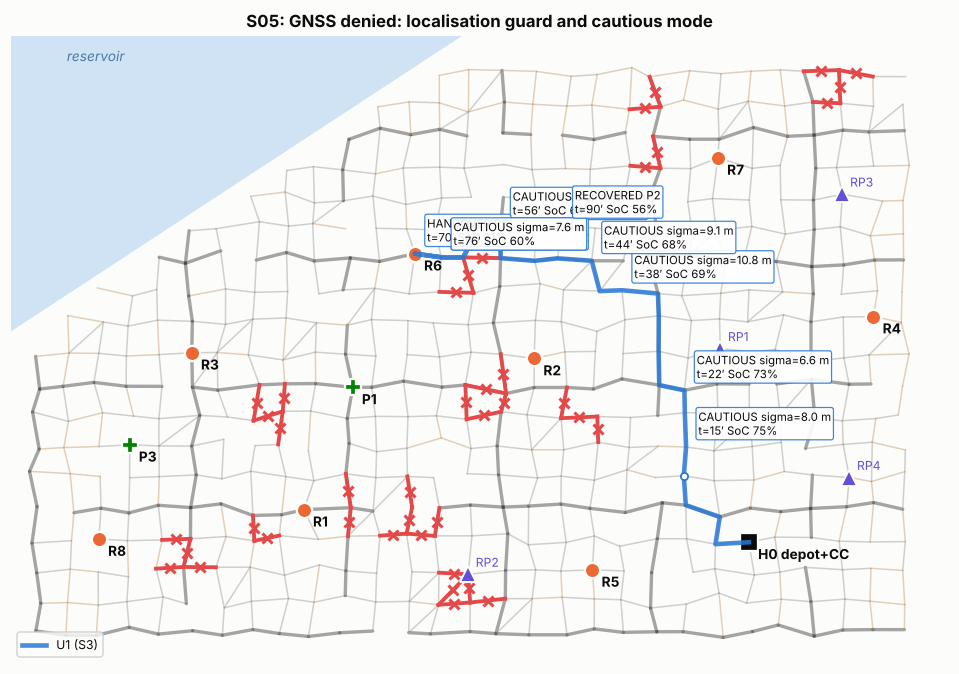

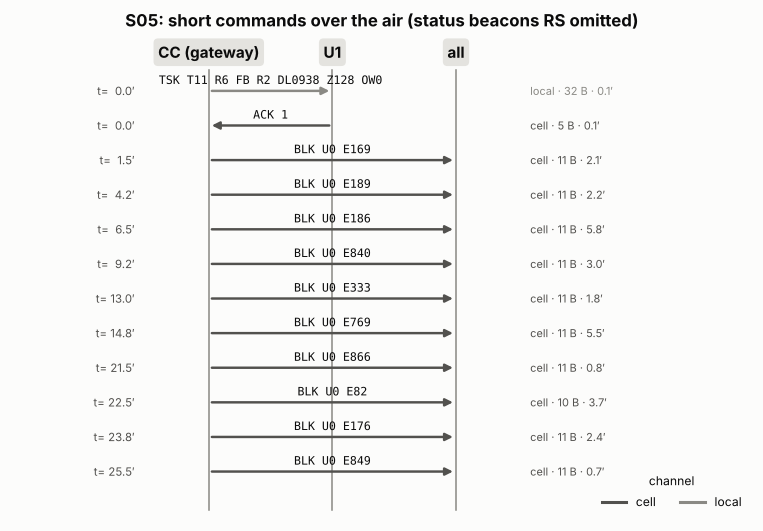

,robot,strategy,terminal,valid,on_time,soc_end,dist_km,lat,n_packets,airtime_s
0,U1,S3,recovered,1,1,0.56,7.51,0.04,12,0.53


,agent,"t, min",node,decision,info,SoC
0,U1,14.7,195,CAUTIOUS,sigma=8.0 m,75%
1,U1,20.2,224,NOMINAL,sigma=3.0 m,74%
2,U1,22.2,253,CAUTIOUS,sigma=6.6 m,73%
3,U1,26.1,252,NOMINAL,sigma=3.0 m,72%
4,U1,37.8,335,CAUTIOUS,sigma=10.8 m,69%
5,U1,41.1,334,NOMINAL,sigma=3.0 m,69%
6,U1,44.1,359,CAUTIOUS,sigma=9.1 m,68%
7,U1,48.7,358,NOMINAL,sigma=3.0 m,67%
8,U1,56.1,380,CAUTIOUS,sigma=9.9 m,64%
9,U1,65.0,355,NOMINAL,sigma=3.0 m,62%


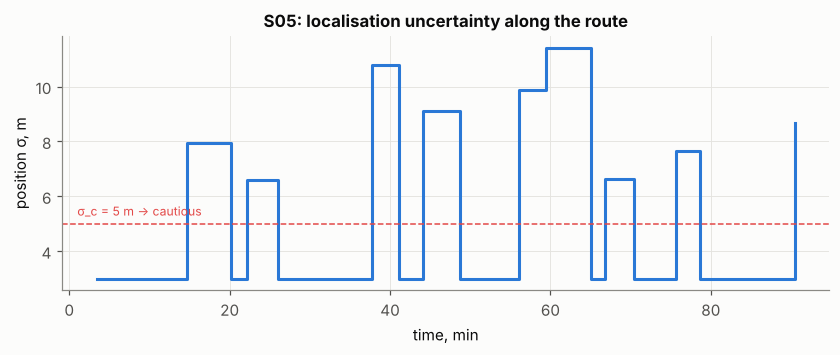

In [17]:
sim = run_scenario(w, "S05")
show(sim, "S05", seq_msgs=12)
r = sim.robots[0]
fig, ax = plt.subplots(figsize=(9, 3))
ax.step([x[0] for x in r.trace], [x[5] for x in r.trace], where="post", color=viz.C["blue"], lw=2, label="σ, m")
ax.axhline(5, color=viz.C["red"], ls="--", lw=1); ax.text(1, 5.3, "σ_c = 5 m → cautious", color=viz.C["red"], fontsize=8)
ax.set_xlabel("time, min"); ax.set_ylabel("position σ, m"); ax.set_title("S05: localisation uncertainty along the route")
save(fig, "scenario_S05_sigma.png")

### S06 — зміна флоту з переривчастим зв'язком (C2)
4 роботи, 8 год, заявки `REQ` від пунктів (Пуассон 2.4/год). **Централізована** політика бере заявки лише в депо. **Агентна** додає запасні одиниці вантажу, підбір заявок від вузлів пунктів по дорозі (DTN), обмін P2P та аукціон `BID → LSE`.

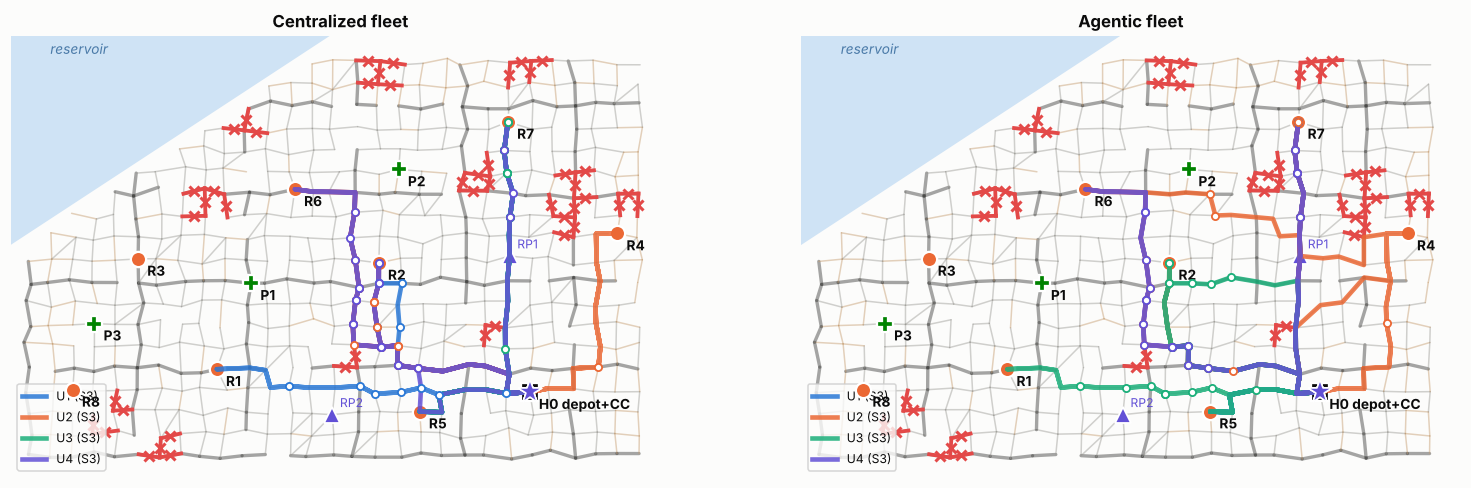

,policy,n,service,delivered,aware_med,lat_med,km_per,stranded,dups,packets,gw_air
0,C,17,0.53,1.0,89.77,0.12,6.58,0,0,165,0.60
1,A,17,0.71,1.0,69.89,0.13,6.56,0,0,193,0.94


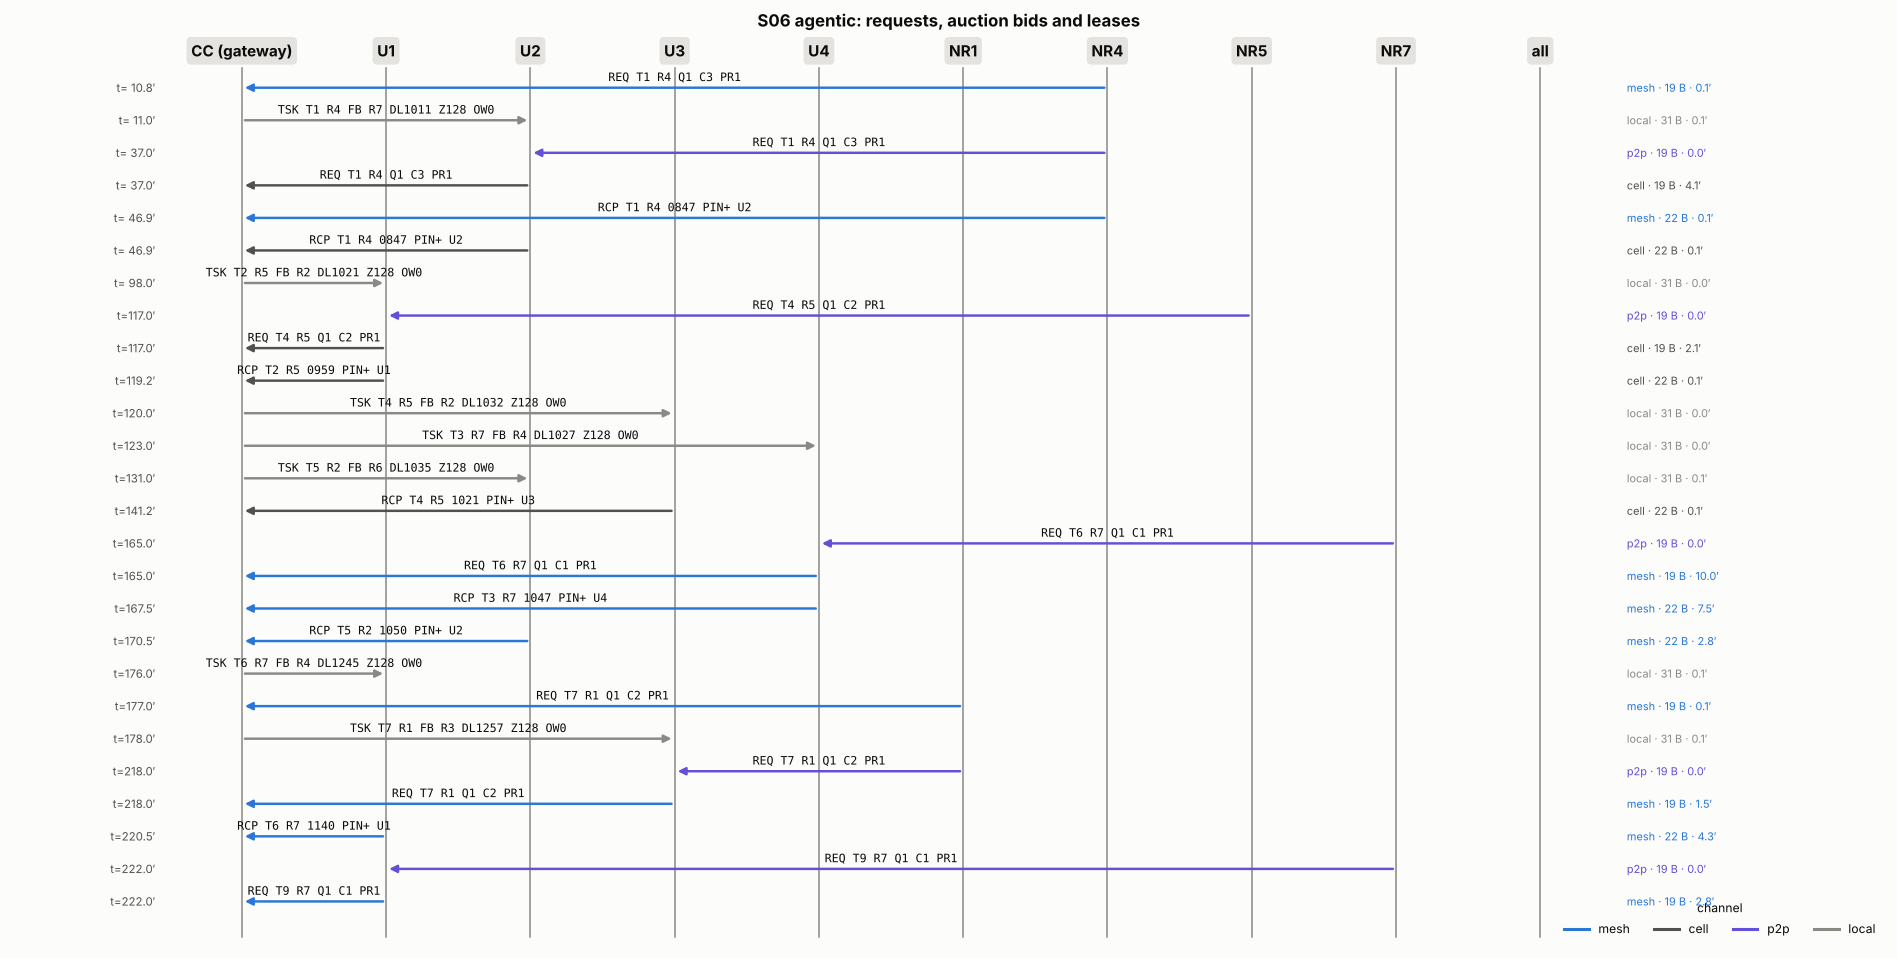

In [18]:
res = {}
for pol in ["C", "A"]:
    res[pol] = run_scenario(w, "S06", policy=pol)
fig, axs = plt.subplots(1, 2, figsize=(17, 6.4))
for ax, pol in zip(axs, ["C", "A"]):
    viz.plot_mission(res[pol], ax, title=("Centralized" if pol == "C" else "Agentic") + " fleet", annotate=False)
save(fig, "scenario_S06_fleet_maps.png")
display(pd.DataFrame([FleetLogic.metrics(res[p]) for p in ["C", "A"]]).round(2))
ax = viz.sequence_diagram(res["A"], max_msgs=26, skip_ops=("RS", "ACK", "BLK"))
ax.set_title("S06 agentic: requests, auction bids and leases"); save(ax.figure, "scenario_S06_sequence.png")

### S07 — робот-ретранслятор піднімає щоглу
Немає ані стільникового зв'язку, ані ретрансляторів. Планувальник двійника обирає вузол, що найбільше покращує покриття біля пунктів, і надсилає `RLY U9 N…`. Ретранслятор їде туди й піднімає телескопічну щоглу 10 м (`MAST-UP`); квитанція доставки доходить через нього.

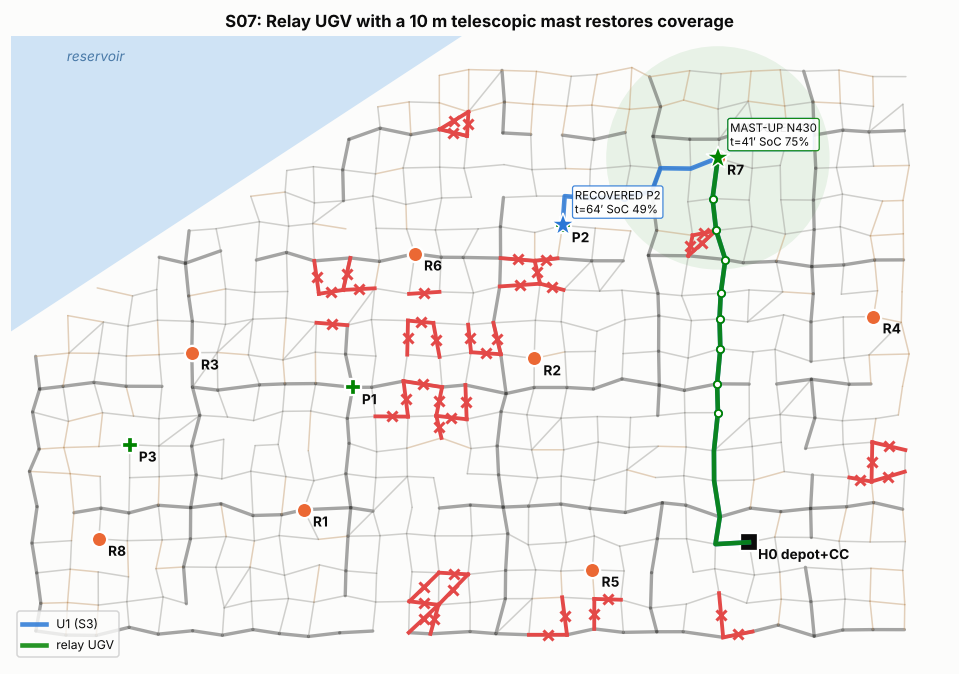

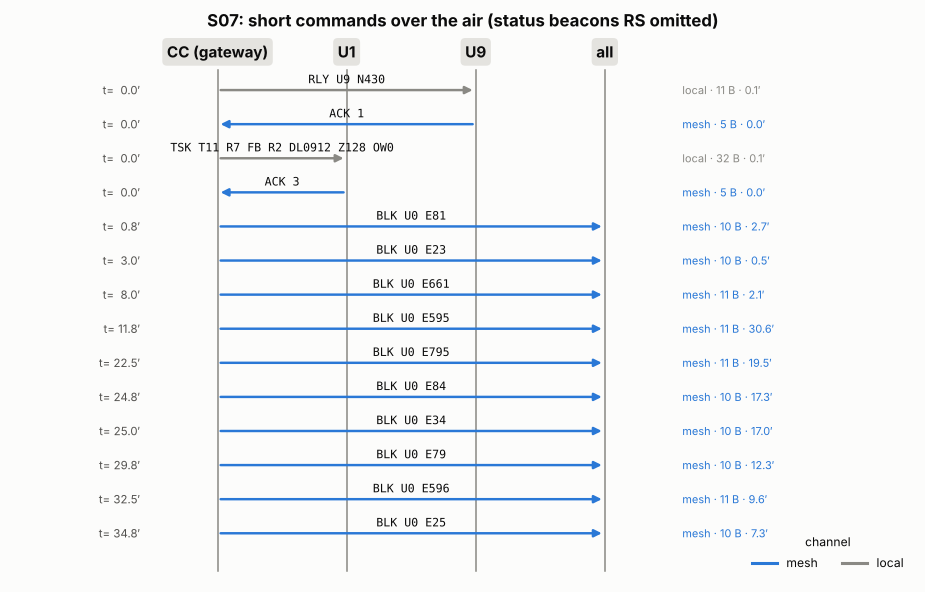

,robot,strategy,terminal,valid,on_time,soc_end,dist_km,lat,n_packets,airtime_s
0,U1,S3,recovered,1,1,0.49,5.77,0.02,6,0.51


,agent,"t, min",node,decision,info,SoC
0,U1,41.5,430,HANDOVER,R7,55%
1,U1,63.9,382,RECOVERED,P2,49%
2,U9,41.5,430,MAST-UP,N430,75%


receipt latency with relay: 0.0 min, without: 11.0 min
share of route nodes with contact: with relay 50 %, without 30 %


In [19]:
sim7 = run_scenario(w, "S07"); show(sim7, "S07", seq_msgs=14)
base = run_scenario(w, "S07", relay=False)
share = lambda s: np.mean([x[4] for x in s.robots[0].trace])
print("receipt latency with relay: %.1f min, without: %.1f min" % (sim7.mission_metrics()[0]["lat"], base.mission_metrics()[0]["lat"]))
print("share of route nodes with contact: with relay %.0f %%, without %.0f %%" % (100 * share(sim7), 100 * share(base)))

### S08 — розвезення води по трьох пунктах
Вантаж 30 кг, −14 °C, сніг. Контракти `TSK` на три пункти. SFC перевіряє весь ланцюг $x\to d_1\to d_2\to d_3\to\rho^*$; якщо він нездійсненний, відкидає останню зупинку (`DEC U1 DRP R3`) і повідомляє ЦКК — завдання перерозподіляють.

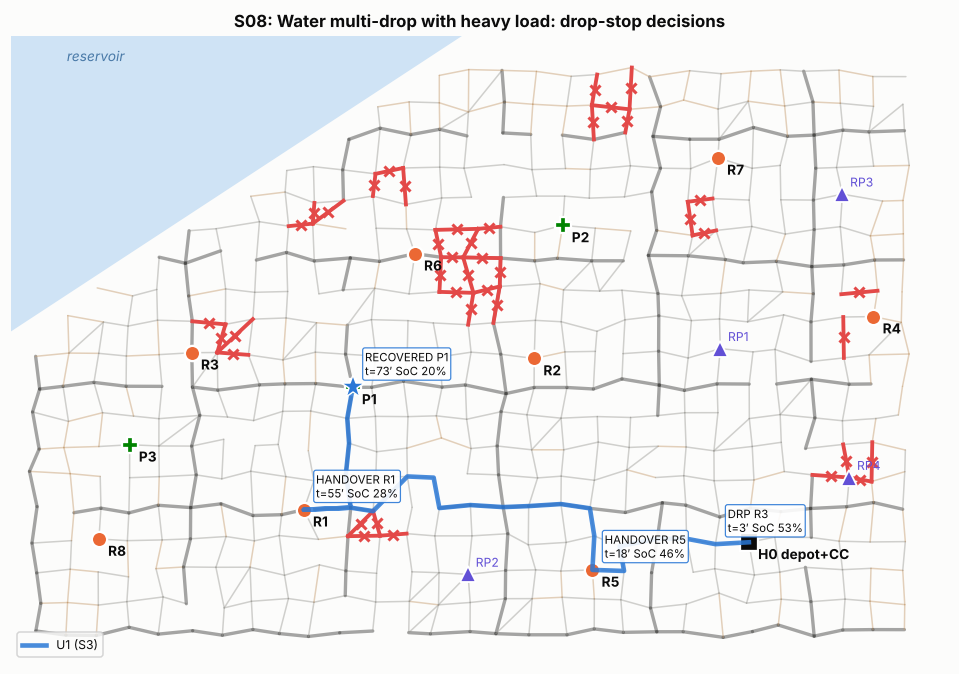

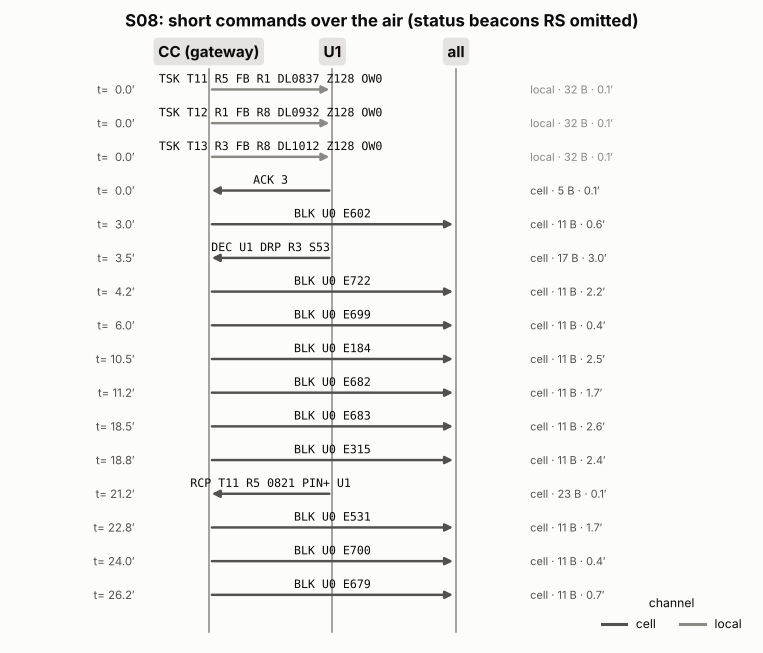

,robot,strategy,terminal,valid,on_time,soc_end,dist_km,lat,n_packets,airtime_s
0,U1,S3,recovered,2,2,0.2,6.8,0.08,12,0.35


,agent,"t, min",node,decision,info,SoC
0,U1,3.5,109,DRP,R3,53%
1,U1,18.2,76,HANDOVER,R5,46%
2,U1,55.5,125,HANDOVER,R1,28%
3,U1,72.8,242,RECOVERED,P1,20%


In [20]:
show(run_scenario(w, "S08"), "S08", seq_msgs=16)

### S09 — перевантаження ефіру: періодичні звіти проти звітів за подіями
Шість роботів, MEDIUM_FAST, статус щохвилини з підтвердженням. Шлюз ЦКК підходить до межі 36 с/год. На 60-й хвилині Comms steward розсилає `RPT 0` — роботи переходять на звіти за подіями, і завантаження шлюзу падає.

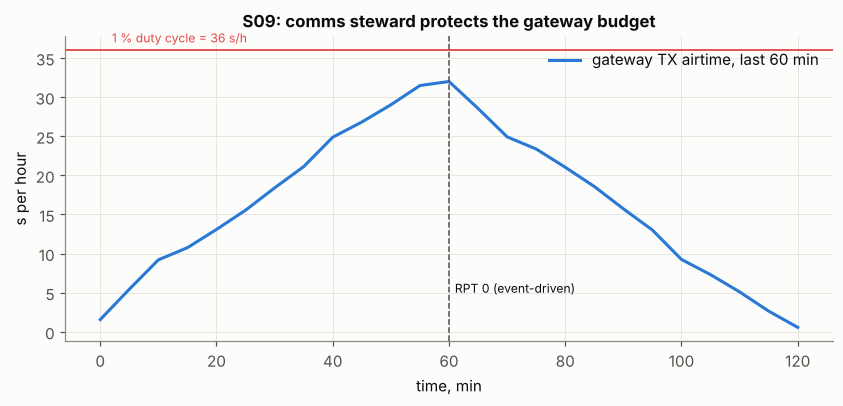

ACK    33.68
RPT     0.44
Name: gateway airtime by message, s, dtype: float64

In [21]:
sim9 = run_scenario(w, "S09")
tt = np.arange(0, 121, 5)
use = [sim9.gw_budget_used(t, 60.0) for t in tt]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(tt, use, color=viz.C["blue"], lw=2, label="gateway TX airtime, last 60 min")
ax.axhline(36, color=viz.C["red"], lw=1.2); ax.text(2, 37, "1 % duty cycle = 36 s/h", color=viz.C["red"], fontsize=8)
ax.axvline(60, color=viz.C["ink2"], ls="--", lw=1); ax.text(61, 5, "RPT 0 (event-driven)", fontsize=8)
ax.set_xlabel("time, min"); ax.set_ylabel("s per hour"); ax.set_title("S09: comms steward protects the gateway budget"); ax.legend()
save(fig, "scenario_S09_airtime.png")
pd.Series({op: round(sum(s for _, s, o in sim9.gw_tx if o == op), 2) for op in sorted(set(o for _, _, o in sim9.gw_tx))},
          name="gateway airtime by message, s")

### S10 — людина в контурі: регулятор ризику, утримання, відкликання
Оператор підвищує рівень ризику `ZSET 233` (z = 2.33, обережніше), тимчасово утримує робота `HLD U1 MIN10`, а потім відкликає його `RTB U1 P1`. Робот підкоряється, якщо команда дійшла; монітор безпеки зберігає право зупинки.

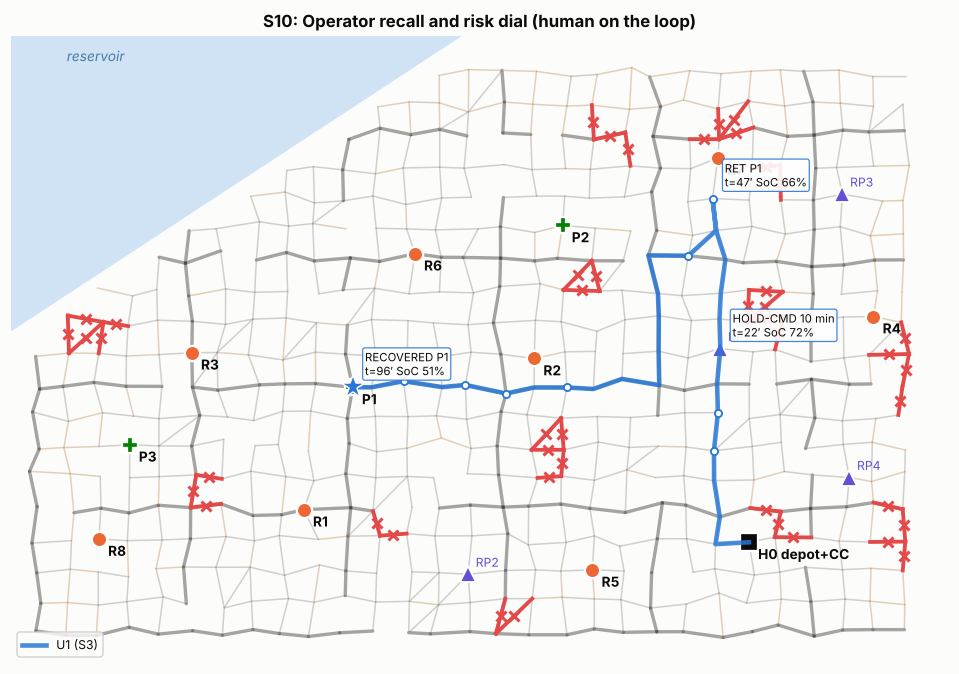

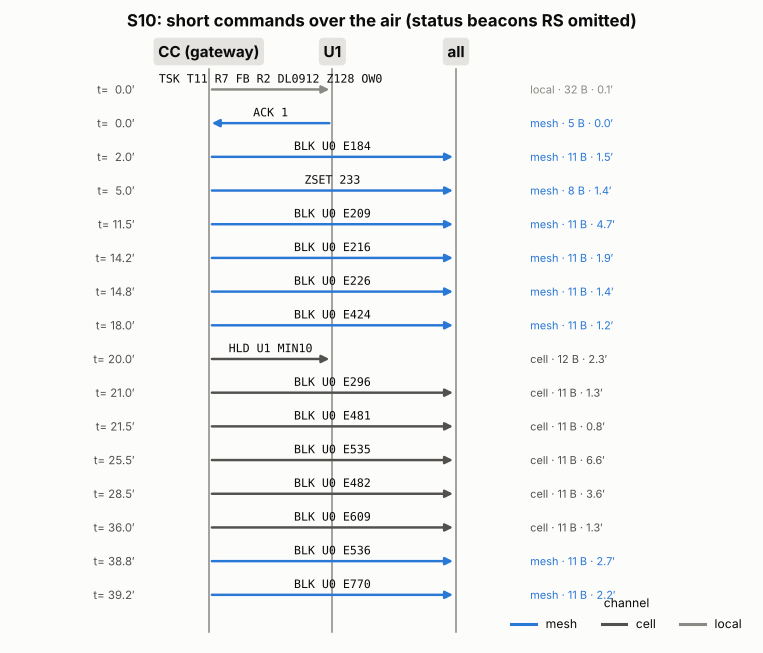

,robot,strategy,terminal,valid,on_time,soc_end,dist_km,lat,n_packets,airtime_s
0,U1,S3,recovered,0,0,0.51,8.62,NaN,9,0.63


,agent,"t, min",node,decision,info,SoC
0,U1,22.2,283,HOLD-CMD,10 min,72%
1,U1,47.3,409,RET,P1,66%
2,U1,95.7,242,RECOVERED,P1,51%


In [22]:
show(run_scenario(w, "S10"), "S10", seq_msgs=16)

## 7. Парний Монте-Карло: S1 / S2 / S3

Факторний план (зменшений для Colab): заряд $SoC_0 \in \{30, 50, 70, 90\}\%$ × вік знеструмлення $H \in \{6, 72\}$ год × ретранслятори $k \in \{0, 4\}$ × 8 повторів; частка перекриттів, пункт призначення, погода, GNSS, закриття пунктів — випадкові, але **спільні для всіх стратегій** (парний дизайн). Для публікаційних інтервалів збільште `reps`.

384 missions in 17 s


,missions,on-time %,valid %,stranded %,recovered %,SoC at end %,"receipt latency, min (median)"
strategy,,,,,,,
S1,128,35.2,41.4,71.9,28.1,28.9,0.1
S2,128,82.8,82.8,34.4,65.6,29.9,0.1
S3,128,73.4,73.4,0.0,81.2,41.2,0.1


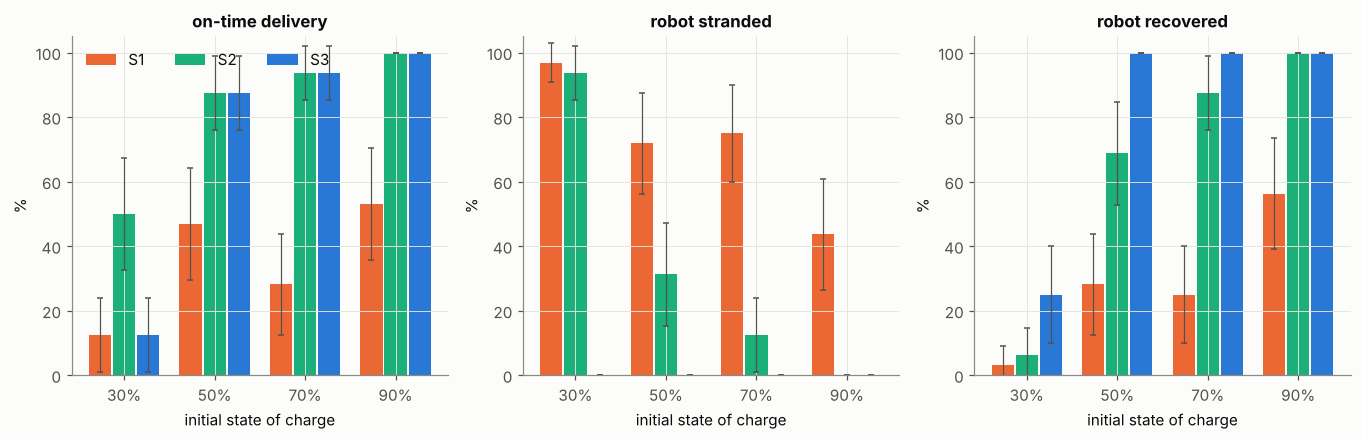

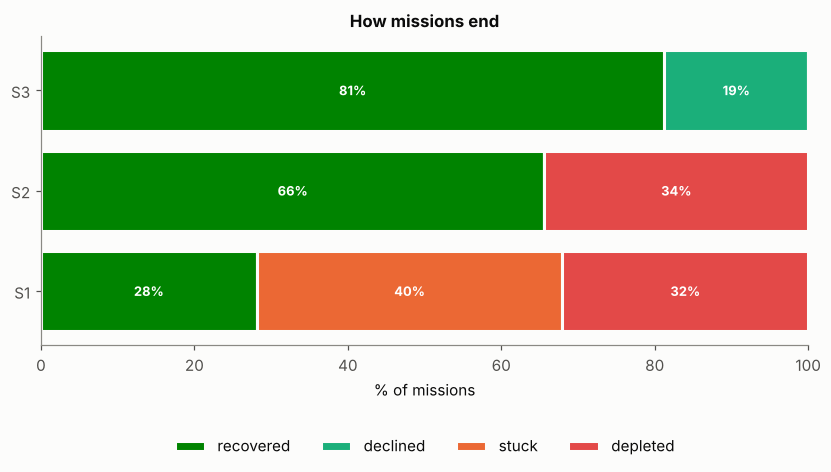

In [23]:
t0 = time.time()
dfA = ex.single_missions(w, reps=8)
print(f"{len(dfA)} missions in {time.time()-t0:.0f} s")
display(ex.summary_table(dfA))
save(ex.plot_single(dfA), "mc_single_missions.png")
save(ex.outcome_mix(dfA), "mc_outcomes.png")

In [24]:
# paired difference S3 - S1 / S3 - S2 in on-time delivery, bootstrap CI
piv = dfA.pivot_table(index=["seed", "H", "k"], columns="strategy", values="on_time")
rng = np.random.default_rng(0)
for base in ["S1", "S2"]:
    d = (piv["S3"] - piv[base]).values
    bs = [rng.choice(d, len(d)).mean() for _ in range(1000)]
    print(f"on-time S3 - {base}: {100*d.mean():+.1f} pp  (95% CI {100*np.percentile(bs, 2.5):+.1f} .. {100*np.percentile(bs, 97.5):+.1f})")
print("\nby outage age H and repeaters k (on-time %, stranded %):")
display((100 * dfA.groupby(["strategy", "H", "k"])[["on_time", "stranded"]].mean()).round(0).unstack("strategy"))

on-time S3 - S1: +38.3 pp  (95% CI +29.7 .. +46.9)
on-time S3 - S2: -9.4 pp  (95% CI -14.8 .. -4.7)

by outage age H and repeaters k (on-time %, stranded %):


on_time             stranded           
strategy      S1    S2    S3       S1    S2   S3
H  k                                            
6  0        38.0  75.0  69.0     69.0  38.0  0.0
   4        66.0  91.0  78.0     50.0  31.0  0.0
72 0         9.0  75.0  69.0     91.0  38.0  0.0
   4        28.0  91.0  78.0     78.0  31.0  0.0

### 7.1 Регулятор ризику z
Більше $z$ — більший резерв енергії і менше прийнятих місій. Дозвіл односторонньої доставки (one-way) додає доставки ціною того, що робот може залишитися на пункті видачі. У цьому двійнику навіть $z = 0$ майже не дає застрягань: решту ризику покривають онлайн-калібрування $\hat r_t$, фіксований резерв $\epsilon$ і перевірка на кожному вузлі, тож регулятор здебільшого змінює частку відмов.

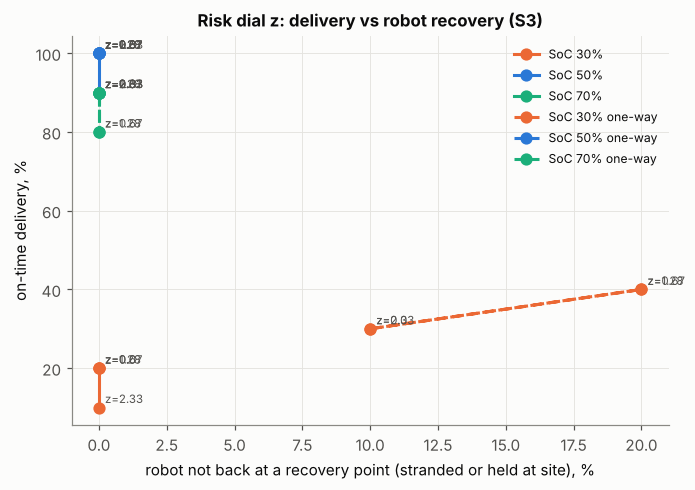

on_time       stranded      
oneway   False True     False True 
z                                  
0.00      70.0  73.3      0.0   0.0
0.67      70.0  73.3      0.0   0.0
1.28      70.0  73.3      0.0   0.0
2.33      63.3  73.3      0.0   0.0

In [25]:
dfB = ex.risk_dial(w, reps=10)
save(ex.plot_risk_dial(dfB), "mc_risk_dial.png")
(100 * dfB.groupby(["oneway", "z"])[["on_time", "stranded"]].mean()).round(1).unstack("oneway")

## 8. Флот: централізоване проти агентного керування

Одна зміна 8 год, 4 роботи, вік знеструмлення 72 год (більшість базових станцій уже без резерву), $k\in\{0,4,8\}$. Метрики: частка заявок, виконаних вчасно (дедлайн 120 хв), медіанний час, доки про заявку дізнався хтось із системи, затримка підтвердження доставки.

60 shifts in 19 s


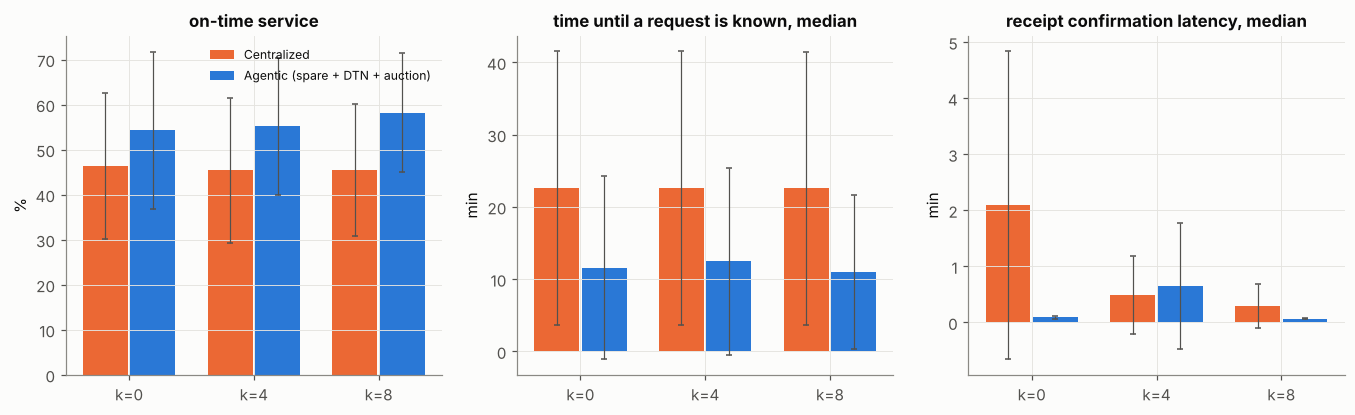

service  delivered  aware_med  lat_med  km_per  dups  packets  gw_air
policy k                                                                       
A      0     0.54       0.79      11.61     0.09    7.18   0.0    206.1    2.25
       4     0.55       0.81      12.48     0.65    7.24   0.0    224.7    2.18
       8     0.58       0.81      10.98     0.07    7.30   0.0    239.1    2.38
C      0     0.46       0.74      22.58     2.09    7.76   0.0    146.1    1.24
       4     0.45       0.75      22.57     0.49    7.73   0.0    162.2    1.15
       8     0.45       0.76      22.56     0.29    7.74   0.0    178.9    1.32

In [26]:
t0 = time.time()
dfF = ex.fleet_experiment(w, reps=10)
print(f"{len(dfF)} shifts in {time.time()-t0:.0f} s")
save(ex.plot_fleet(dfF), "fleet_policies.png")
dfF.groupby(["policy", "k"])[["service", "delivered", "aware_med", "lat_med", "km_per", "dups", "packets", "gw_air"]].mean().round(2)

## 9. Нейрорішення

Чотири невеликі нейромережі (багатошарові перцептрони, реалізовані на чистому NumPy, оптимізатор Adam) доповнюють, але **не замінюють** перевірювані правила:

| Модуль | Вхід | Вихід | Де використовується |
|---|---|---|---|
| **N1 EnergyEnsemble** | ознаки ділянки (довжина, підйом, тип покриття, прогноз снігу, температура, κ, вантаж, фізичний прогноз) | середнє і σ відношення «факт / фізика» (5 мереж, гаусова NLL) | замість фізичного прогнозу в ймовірнісному обмеженні SFC (стратегія **S3N**) |
| **N2 PolicyNet** | 13 ознак стану в епосі рішення | CONTINUE / RETURN / STOP | нейрополітика під **щитом** предикатів SFC (стратегія **NNP**) |
| **N3 ContactNet** | геометрія вузла відносно інфраструктури | P(контакт mesh) | карти покриття, вибір місця маяка, comm-aware маршрути |
| **N4 IntentNet** | вільний текст оператора (UA/EN) | намір + слоти → коротка команда | порадник оператора; команда проходить валідатор |

Принцип **runtime assurance (Simplex)**: мережа пропонує, перевірений щит вирішує.

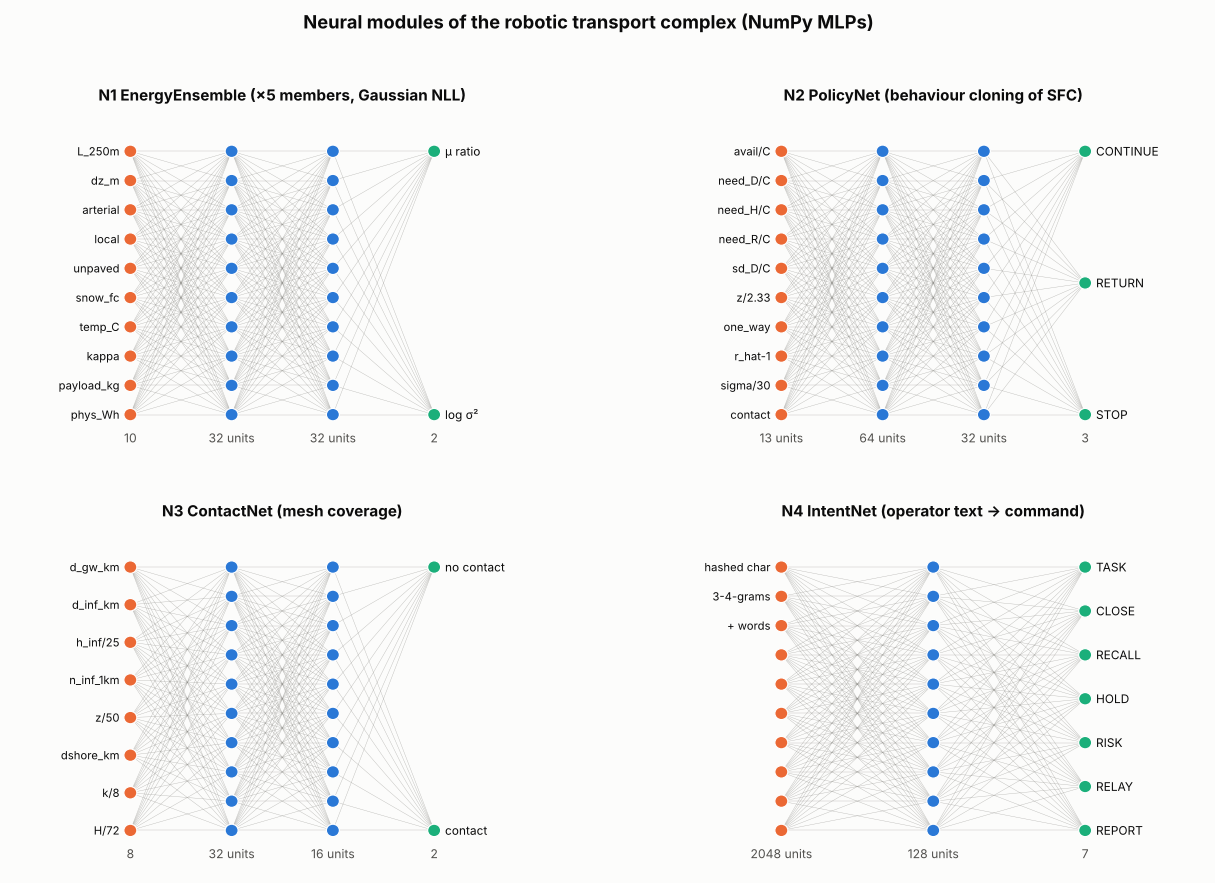

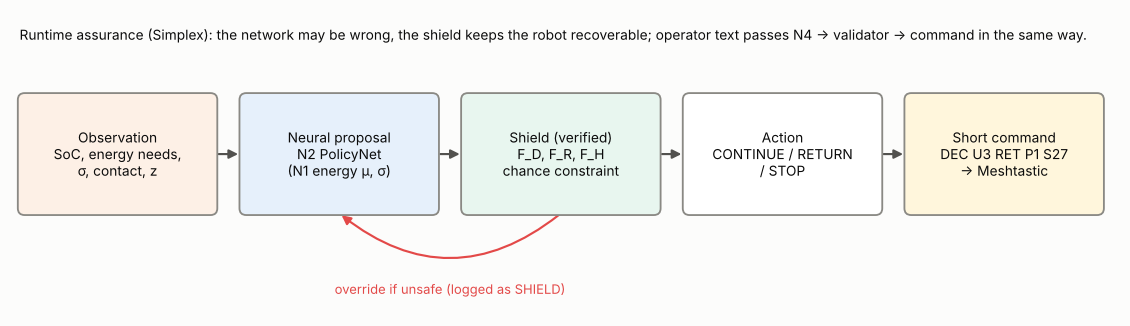

In [27]:
save(viz.neural_overview_figure(), "neural_architectures.png")
save(viz.shield_pipeline_figure(), "neural_shield_pipeline.png")

### 9.1 N1 — глибокий ансамбль для прогнозу енергії
Дані — «телеметрія» з 160 синтетичних змін. Ціль — відношення справжньої енергії до фізичного прогнозу. Ансамбль з 5 мереж (bootstrap) дає **алеаторну** (σ шуму) і **епістемічну** (розкид членів) невизначеність; їх сума йде в рівняння 5 замість $\sigma_e\hat e_a$.

trained in 10 s; parameters per member: 1474
RMSE of energy ratio: physics 0.192 -> ensemble 0.136 (noise floor ~0.10); share inside ±1σ: 68%, ±2σ: 95%


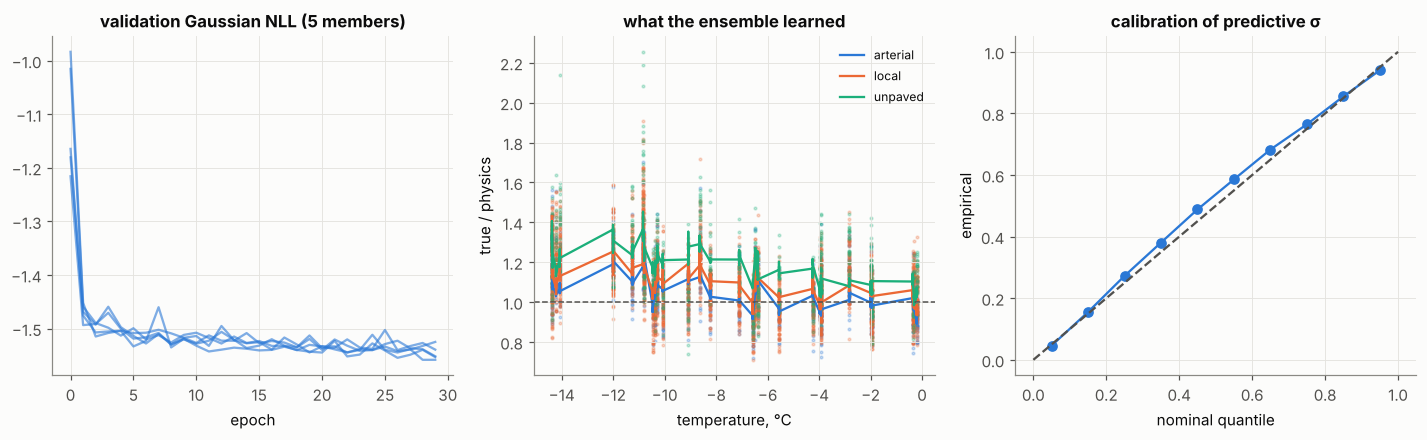

In [28]:
t0 = time.time()
Xe, ye = nn.make_energy_dataset(w, n_scen=160)
Xe_t, ye_t = nn.make_energy_dataset(w, n_scen=30, seed=5)
ens = nn.EnergyEnsemble().fit(Xe, ye, epochs=30)
mu, sd, epi = ens.predict_ratio(Xe_t)
print(f"trained in {time.time()-t0:.0f} s; parameters per member: {ens.members[0].n_params()}")
print(f"RMSE of energy ratio: physics {np.sqrt(((1-ye_t)**2).mean()):.3f} -> ensemble {np.sqrt(((mu-ye_t)**2).mean()):.3f}"
      f" (noise floor ~0.10); share inside ±1σ: {(abs(mu-ye_t) < sd).mean():.0%}, ±2σ: {(abs(mu-ye_t) < 2*sd).mean():.0%}")
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for m in ens.members:
    h = np.array(m.history); axs[0].plot(h[:, 0], h[:, 2], color=viz.C["blue"], alpha=0.6)
axs[0].set_title("validation Gaussian NLL (5 members)"); axs[0].set_xlabel("epoch")
cls = Xe_t[:, 2:5].argmax(1)
for c, (name, col) in enumerate(zip(["arterial", "local", "unpaved"], [viz.C["blue"], viz.C["orange"], viz.C["aqua"]])):
    k = cls == c
    axs[1].scatter(Xe_t[k, 6], ye_t[k], s=3, alpha=0.25, color=col)
    o = np.argsort(Xe_t[k, 6]); axs[1].plot(Xe_t[k, 6][o], mu[k][o], color=col, lw=1.5, label=name)
axs[1].axhline(1, color=viz.C["ink2"], ls="--", lw=1); axs[1].set_xlabel("temperature, °C"); axs[1].set_ylabel("true / physics")
axs[1].set_title("what the ensemble learned"); axs[1].legend(fontsize=8)
q = np.linspace(0.05, 0.95, 10); from math import erf
z = (ye_t - mu) / sd; emp = [(z < np.quantile(np.random.default_rng(0).standard_normal(100000), qq)).mean() for qq in q]
axs[2].plot(q, emp, "o-", color=viz.C["blue"]); axs[2].plot([0, 1], [0, 1], "--", color=viz.C["ink2"])
axs[2].set_xlabel("nominal quantile"); axs[2].set_ylabel("empirical"); axs[2].set_title("calibration of predictive σ")
save(fig, "nn_energy_ensemble.png")

### 9.2 N2 — нейрополітика, клонована з SFC, під щитом
Збираємо пари «ознаки епохи → рішення SFC» з 300 випадкових місій (лише епохи з відкритою доставкою — саме там ухвалюється рішення «продовжити чи повернутися»), навчаємо класифікатор і запускаємо його як керувальника. Щит блокує CONTINUE, якщо $F_D$ хибний, і RETURN, якщо $F_R$ хибний.

3889 decision epochs, classes {'CONTINUE': np.int64(3810), 'RETURN': np.int64(79), 'STOP': np.int64(0)}; trained in 23 s
held-out accuracy 0.995


PolicyNet,CONTINUE,RETURN
SFC,,
CONTINUE,757,2
RETURN,2,17


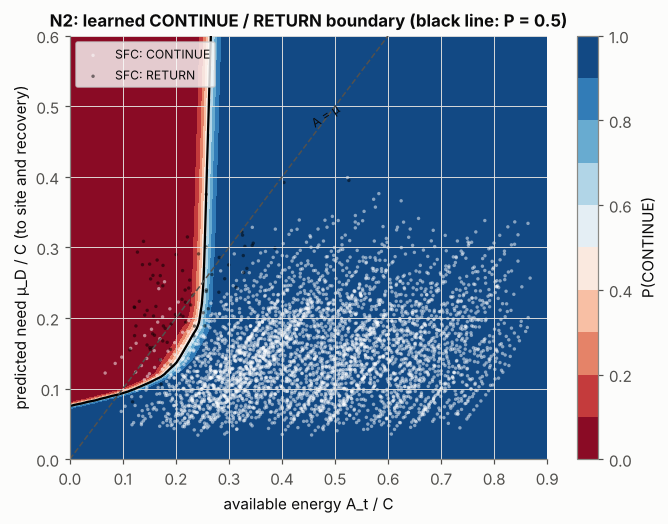

In [29]:
t0 = time.time()
Xp, yp = nn.collect_sfc_epochs(w, n=300)
idx = np.random.default_rng(0).permutation(len(Xp)); ntr = int(0.8 * len(Xp))
pol = nn.PolicyNet().fit(Xp[idx[:ntr]], yp[idx[:ntr]], epochs=80)
pred = pol.proba(Xp[idx[ntr:]]).argmax(1); yt = yp[idx[ntr:]]
print(f"{len(Xp)} decision epochs, classes {dict(zip(nn.ACTIONS_NN, np.bincount(yp, minlength=3)))}; trained in {time.time()-t0:.0f} s")
print(f"held-out accuracy {np.mean(pred == yt):.3f}")
cm = pd.crosstab(pd.Series([nn.ACTIONS_NN[i] for i in yt], name="SFC"), pd.Series([nn.ACTIONS_NN[i] for i in pred], name="PolicyNet"))
display(cm)
# decision map over (available energy, predicted need), other features at their median
f0 = np.median(Xp, axis=0); A = np.linspace(0, 0.9, 150); Nd = np.linspace(0, 0.6, 150)
aa, nd = np.meshgrid(A, Nd); grid = np.tile(f0, (aa.size, 1))
grid[:, 0] = aa.ravel(); grid[:, 1] = nd.ravel(); grid[:, 2] = 0.55 * nd.ravel(); grid[:, 4] = 0.06 * nd.ravel()
P = pol.proba(grid)[:, 0].reshape(aa.shape)
fig, ax = plt.subplots(figsize=(7, 5))
cs = ax.contourf(aa, nd, P, levels=np.linspace(0, 1, 11), cmap="RdBu")
ax.contour(aa, nd, P, levels=[0.5], colors="k", linewidths=1.5)
ax.plot([0, 0.6], [0, 0.6], color=viz.C["ink2"], lw=1, ls="--"); ax.text(0.45, 0.47, "A = μ", rotation=33, fontsize=8)
for c, col, lab in ((0, "white", "SFC: CONTINUE"), (1, "black", "SFC: RETURN")):
    k = yp == c; ax.scatter(Xp[k, 0], Xp[k, 1], s=5, color=col, alpha=0.5, label=lab, edgecolors="none")
plt.colorbar(cs, label="P(CONTINUE)"); ax.set_xlabel("available energy A_t / C"); ax.set_ylabel("predicted need μ_D / C (to site and recovery)")
ax.set_xlim(0, 0.9); ax.set_ylim(0, 0.6); ax.legend(loc="upper left", fontsize=8, frameon=True)
ax.set_title("N2: learned CONTINUE / RETURN boundary (black line: P = 0.5)"); save(fig, "nn_policy_boundary.png")

### 9.3 Порівняння S3 · S3N (SFC + N1) · NNP (N2 + щит)

240 missions in 18 s; shield interventions: 0


on_time               stranded           mid_abort            
strategy     NNP     S3    S3N      NNP   S3  S3N       NNP    S3   S3N
soc0                                                                   
0.30         0.0    0.0    0.0      0.0  0.0  0.0       0.0   0.0   0.0
0.45        45.0   50.0   55.0      0.0  0.0  0.0      25.0  40.0  45.0
0.60       100.0  100.0  100.0      0.0  0.0  0.0       0.0   0.0   0.0
0.80       100.0  100.0  100.0      0.0  0.0  0.0       0.0   0.0   0.0

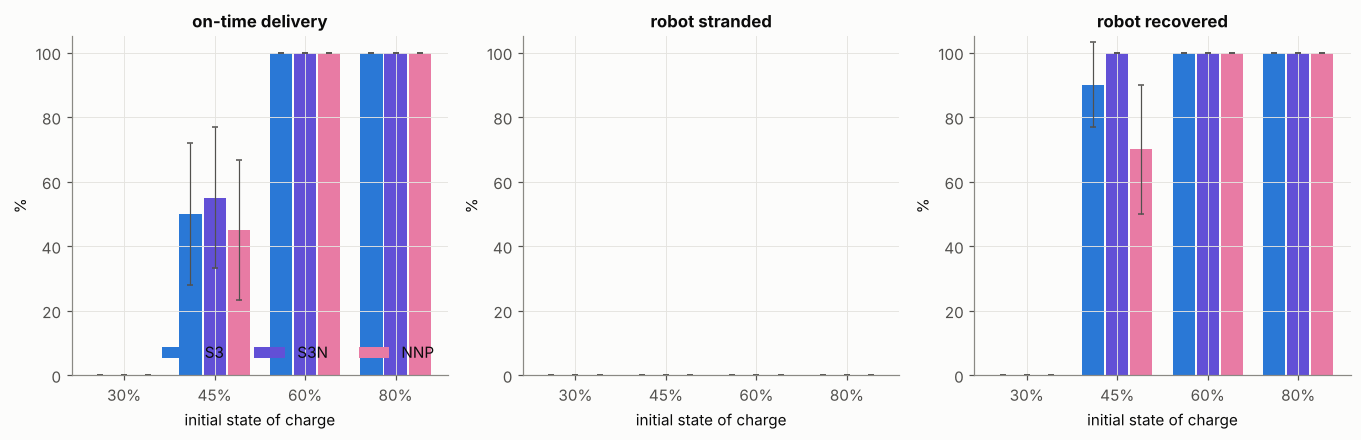

In [30]:
t0 = time.time()
dfN, shield = ex.neural_comparison(w, ens, pol, reps=20)
print(f"{len(dfN)} missions in {time.time()-t0:.0f} s; shield interventions: {len(shield)}")
display((100 * dfN.groupby(["strategy", "soc0"])[["on_time", "stranded", "mid_abort"]].mean()).round(0).unstack("strategy"))
save(ex.plot_single(dfN), "nn_strategy_comparison.png")
if shield:
    display(pd.DataFrame(shield, columns=["t", "robot", "proposed", "executed"]).head(10))

**Стрес-тест щита.** Що буде, якщо мережа помиляється? Візьмемо (а) «самовпевнену» версію N2, яка повертається лише при P(RETURN) > 0.97, і (б) **несправну** мережу, яка завжди каже CONTINUE, та запустимо їх зі щитом і без нього на місіях із зарядом 30–50 %.

In [31]:
class Overconfident:
    def __init__(self, base): self.base = base
    def act(self, f): return "RETURN" if self.base.proba(f)[0, 1] > 0.97 else "CONTINUE"
class Faulty:
    def act(self, f): return "CONTINUE"
rows = []
for name, model in (("overconfident N2", Overconfident(pol)), ("faulty: always CONTINUE", Faulty())):
    for shield_on in (True, False):
        for soc in (0.3, 0.4, 0.5):
            for r in range(15):
                cfg = Config(soc0=soc, H=24, k=2, b=0.1, policy_model=model, shield=shield_on)
                sim_ = Sim(w, cfg, seed=90_000 + r + int(soc * 100), strategy="NNP").run()
                m = sim_.mission_metrics()[0]
                rows.append(dict(network=name, shield="on" if shield_on else "off", terminal=m["terminal"],
                                 on_time=m["on_time"], overrides=len(sim_.shield_events)))
dfS = pd.DataFrame(rows)
tab = pd.crosstab([dfS.network, dfS.shield], dfS.terminal)
tab["on-time %"] = (100 * dfS.groupby(["network", "shield"]).on_time.mean()).round(0)
tab["shield overrides"] = dfS.groupby(["network", "shield"]).overrides.sum()
tab

terminal                        declined  depleted  recovered  stopped  on-time %  shield overrides
network                 shield                                                                     
faulty: always CONTINUE off            0        11         24       10       76.0                 0
                        on            23         0         22        0       42.0                26
overconfident N2        off           25         0         20        0       42.0                 0
                        on            25         0         20        0       40.0                 1

Без щита несправна мережа доставляє частіше, але приблизно половина роботів **розряджається в дорозі або зупиняється з маяком** далеко від пункту повернення. Зі щитом жоден робот не втрачений: небезпечні CONTINUE замінюються на RETURN (або відмову в депо). Це і є сенс runtime assurance: якість нейромережі впливає на ефективність, але не на безпеку.

### 9.4 N3 — нейропрогноз покриття mesh

Brier score: constant 0.244 -> ContactNet 0.144; accuracy 0.786


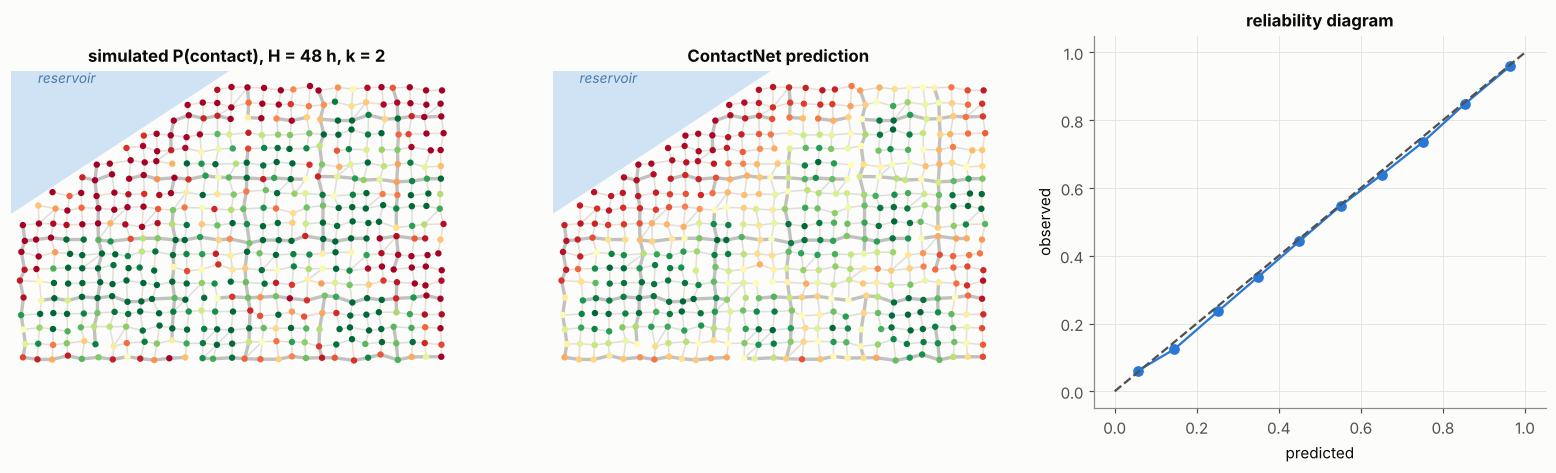

In [32]:
Xc, yc = nn.make_contact_dataset(w, n_scen=50)
Xc_t, yc_t = nn.make_contact_dataset(w, n_scen=12, seed=3)
cnet = nn.ContactNet().fit(Xc, yc, epochs=20)
pc = cnet.proba(Xc_t)
print(f"Brier score: constant {((yc_t.mean()-yc_t)**2).mean():.3f} -> ContactNet {((pc-yc_t)**2).mean():.3f}; accuracy {((pc>0.5)==yc_t).mean():.3f}")
from meshrtc.sim import Scenario
fig, axs = plt.subplots(1, 3, figsize=(18, 4.4))
sc = Scenario(w, Config(H=48, k=2, b=0), 31_000)
emp = np.mean([sc.best_margin + np.random.default_rng(i).normal(0, 4, w.n) > 0 for i in range(200)], axis=0)
pred = cnet.proba(nn.contact_features(w, sc.fab, sc.alive, 48))
for ax, v, t in ((axs[0], emp, "simulated P(contact), H = 48 h, k = 2"), (axs[1], pred, "ContactNet prediction")):
    viz.plot_town(w, ax, sites=False, legend=False, alpha_streets=0.3)
    s = ax.scatter(*w.xy.T, c=v, cmap="RdYlGn", vmin=0, vmax=1, s=10, zorder=3); ax.set_title(t)
bins = np.linspace(0, 1, 11); b = np.digitize(pc, bins) - 1
axs[2].plot([(pc[b == i]).mean() for i in range(10) if (b == i).any()], [(yc_t[b == i]).mean() for i in range(10) if (b == i).any()], "o-", color=viz.C["blue"])
axs[2].plot([0, 1], [0, 1], "--", color=viz.C["ink2"]); axs[2].set_xlabel("predicted"); axs[2].set_ylabel("observed"); axs[2].set_title("reliability diagram")
save(fig, "nn_contact.png")

### 9.5 N4 — від вільного тексту оператора до короткої команди
Синтетичні запити українською та англійською (50 % з помилками набору) → хешовані символьні n-грами → MLP → намір; слоти (пункти, юніти, час, z) витягуються правилами; команда проходить валідатор. Низька впевненість або нестача слотів → команду **не відправляють**, а просять оператора підтвердити.

In [33]:
tr, te = nn.make_intent_dataset()
inet = nn.IntentNet(2048, (128,)).fit(tr, epochs=30)
pt = inet.proba([s for s, _ in te]).argmax(1); yt = np.array([c for _, c in te])
print(f"train {len(tr)}, test {len(te)}, test accuracy {np.mean(pt == yt):.3f}")
rows = []
for s in ["Терміново інсулін до R4, резерв R2, до 13:30", "Пункт R6 закрито, везіть на R1", "recall U3 to P2",
          "U2 зачекати 15 хвилин", "встановити ризик 2.33", "deploy relay U9 at node 133", "звіти тільки за подіями"] + nn.UNSEEN:
    it, conf, cmd, errs = inet.to_command(s)
    rows.append(dict(operator_text=s, intent=it, confidence=round(conf, 2), command=cmd.text() if cmd else "—",
                     bytes=len(cmd.binary()) if cmd else None, send="yes" if not errs else "ask operator: " + "; ".join(errs)))
pd.DataFrame(rows)

train 1368, test 342, test accuracy 1.000


,operator_text,intent,confidence,command,bytes,send
0,"Терміново інсулін до R4, резерв R2, до 13:30",TASK,1.00,TSK T100 R4 FB R2 DL1330 Z164 OW0,11.0,yes
1,"Пункт R6 закрито, везіть на R1",CLOSE,0.95,CLS R6 ALT R1,5.0,yes
2,recall U3 to P2,RECALL,1.00,RTB U3 P2,5.0,yes
3,U2 зачекати 15 хвилин,HOLD,1.00,HLD U2 MIN15,5.0,yes
4,встановити ризик 2.33,RISK,1.00,ZSET 233,4.0,yes
5,deploy relay U9 at node 133,RELAY,1.00,RLY U9 N133,6.0,yes
6,звіти тільки за подіями,REPORT,1.00,RPT 0,4.0,yes
7,"R3 out of service, everything goes to R5 now",RECALL,0.38,—,NaN,ask operator: missing slot
8,"U2 come back to P1, battery is low",TASK,0.52,—,NaN,ask operator: missing slot
9,"R4 потребує антибіотики до 16:00, запасний R6",TASK,1.00,TSK T100 R4 FB R6 DL1600 Z128 OW0,11.0,yes


## 10. Обмеження, відтворюваність, цитування

**Обмеження.** Місто, радіопокриття, попит і енергетика — синтетичні; радіомодель не враховує колізій і правил ретрансляції Meshtastic у деталях (затримка ретрансляції моделюється випадковою); нейромережі навчено на даних того самого двійника, тому їхня перевага — це перевага над *спрощеною* фізичною моделлю цього двійника. Перед польовим пілотом потрібно виміряти радіопокриття, енергоспоживання на реальних покриттях і перевірити маршрути на місцевості.

**Відтворюваність.** Усі генератори мають фіксовані seed; стратегії порівнюються на спільних випадкових числах. Повний прогін: `python scripts/run_all.py` (рисунки в `figures/`), тести: `python -m pytest tests`.

**Структура пакета**

| Модуль | Призначення |
|---|---|
| `meshrtc/protocol.py` | каталог команд, text/binary кодеки, CRC-16, валідатор, ефірний час LoRa, duty cycle |
| `meshrtc/world.py` | синтетичне місто, енергія (рівн. 3), Дейкстра з дисперсією, радіомодель Хата |
| `meshrtc/sim.py` | агенти (ЦКК, робот S1/S2/S3/S3N/NNP), шина повідомлень Meshtastic, сценарна правда |
| `meshrtc/fleet.py` | диспетчування, DTN, P2P, аукціон BID/LSE |
| `meshrtc/scenarios.py` | 10 транспортних сценаріїв |
| `meshrtc/neural.py` | N1–N4 на NumPy |
| `meshrtc/experiments.py`, `viz.py` | експерименти та рисунки |

**Цитування** — див. `CITATION.cff` (після публікації на Zenodo вкажіть DOI).

In [34]:
print("figures written:", len(os.listdir(FIG)))
sorted(os.listdir(FIG))[:60]

figures written: 39


['airtime_budget.png',
 'concept_agent_society.png',
 'concept_architecture.png',
 'concept_authority.png',
 'coverage_vs_repeaters.png',
 'fleet_policies.png',
 'mc_outcomes.png',
 'mc_risk_dial.png',
 'mc_single_missions.png',
 'neural_architectures.png',
 'neural_shield_pipeline.png',
 'nn_contact.png',
 'nn_energy_ensemble.png',
 'nn_policy_boundary.png',
 'nn_strategy_comparison.png',
 'protocol_sizes_airtime.png',
 'scenario_S01_map.png',
 'scenario_S01_sequence.png',
 'scenario_S02_map.png',
 'scenario_S02_sequence.png',
 'scenario_S03_map.png',
 'scenario_S03_sequence.png',
 'scenario_S04_paired.png',
 'scenario_S04_soc.png',
 'scenario_S05_map.png',
 'scenario_S05_sequence.png',
 'scenario_S05_sigma.png',
 'scenario_S06_fleet_maps.png',
 'scenario_S06_sequence.png',
 'scenario_S07_map.png',
 'scenario_S07_sequence.png',
 'scenario_S08_map.png',
 'scenario_S08_sequence.png',
 'scenario_S09_airtime.png',
 'scenario_S10_map.png',
 'scenario_S10_sequence.png',
 'sfc_landscape.png'